# Control de calidad interno del ionograma
## Evaluación de Isolation Forest como complemento a las reglas de Westgard, con métodos de control estadístico de procesos como referencia adicional

**Proyecto Final Integrador**
**Diplomatura en Ciencia de Datos y Análisis Avanzado (UTN)**

**Grupo 35**
**María Jimena Benito Nacir**

**Octubre de 2026**

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jimena-benito-nacir/control-calidad-ionograma/blob/main/TP_Final_Grupo35_Control_Calidad_Interno_Ionograma.ipynb)


## 1. Comprensión del negocio

### 1.1. Contexto

El ionograma (Na, K y Cl) es una determinación relevante en urgencias, evaluación de la función renal y seguimiento del equilibrio hidroelectrolítico.

Antes de liberar resultados de pacientes, el laboratorio procesa un control interno elaborado con un pool de sueros. Sus resultados se evalúan mediante reglas de Westgard y forman parte de la validación bioquímica, junto con los antecedentes de los pacientes y otros elementos del contexto clínico.

### 1.2. Problema

El laboratorio revisa el control interno mediante reglas de Westgard aplicadas a cada analito por separado. Esta evaluación permite identificar valores alejados de la referencia y patrones sostenidos.

Se busca determinar si Isolation Forest aporta información adicional útil para esa revisión, considerando la frecuencia de sus señales y su relevancia bioquímica.

### 1.3. Público

- **Interno:** área de calidad y bioquímicos responsables de decidir si el equipo está en condiciones de liberar resultados.
- **Externo:** médicos solicitantes y pacientes, que dependen de la confiabilidad de los resultados para tomar decisiones clínicas.

### 1.4. Pregunta del proyecto

¿Aporta Isolation Forest información adicional útil como complemento de las reglas de Westgard en el control interno del ionograma?

Su aporte se evalúa mediante la comparación de señales y la revisión bioquímica de casos seleccionados, utilizando EWMA y CUSUM como métodos estadísticos de referencia adicionales.

### 1.5. Indicadores de evaluación

Se utilizan los siguientes indicadores para comparar Westgard, Isolation Forest, EWMA y CUSUM:

- **Cantidad y porcentaje de registros señalados:** frecuencia de señales por método, analito y pool.
- **Coincidencias y señales exclusivas:** mediciones señaladas por varios métodos o únicamente por uno.

Estos resultados se complementan con la revisión bioquímica de casos seleccionados, considerando la secuencia, la línea de base y los eventos documentados.

Los datos reales no incluyen una clasificación independiente de las mediciones como normales o anómalas. Por eso, los indicadores anteriores describen las señales, pero no cuantifican errores confirmados.

Para estimar las métricas propuestas en la preentrega, la sección 16 introduce errores de magnitud conocida en series simuladas con la media, la DE y la resolución de las 24 líneas de base reales. Sobre esas series se calculan:

- **Falsas alarmas:** porcentaje de mediciones estables señaladas y número esperado de mediciones estables señaladas por mes bajo la simulación.
- **Recall, precisión y F1:** por medición, frente a una verdad de referencia conocida.
- **Episodios detectados y mediciones hasta la primera señal:** aproximación al tiempo de detección.
- **AUC-ROC:** capacidad de cada puntaje para ordenar las mediciones con error por encima de las estables, sin depender del umbral.

### 1.6. Restricciones

- Se dispone de un único equipo y nivel de control, elaborado con pools de sueros.
- La referencia del pool es empírica: permite evaluar estabilidad y precisión, pero no exactitud frente a un valor certificado. La evaluación externa de la calidad queda fuera del alcance del proyecto.
- Cada modelo de Isolation Forest se entrena con 20 mediciones por analito y pool, por lo que su evaluación tiene alcance exploratorio.
- No se dispone de una clasificación independiente de errores analíticos.
- Los controles formaron parte de la validación habitual de resultados de pacientes, pero el análisis no incluye esos resultados ni las acciones realizadas en cada corrida.

### 1.7. Hipótesis exploratorias

- **H1:** Westgard e Isolation Forest pueden señalar mediciones diferentes, debido a sus distintos criterios de detección.
- **H2:** EWMA y CUSUM pueden aportar información complementaria sobre desviaciones sostenidas al considerar mediciones sucesivas.
- **H3:** Algunas señales adicionales de Isolation Forest pueden aportar información útil para la revisión del control; su relevancia requiere valoración bioquímica.



## 2. Objetivos y metodología

### 2.1. Objetivo general

Evaluar el aporte de Isolation Forest como complemento de las reglas de Westgard en el control interno del ionograma, utilizando EWMA y CUSUM como referencias adicionales y revisando casos seleccionados con criterio bioquímico.

### 2.2. Objetivos específicos

- Revisar y organizar los registros de Na, K y Cl por pool de control.
- Caracterizar las líneas de base y examinar su adecuación como referencias para el seguimiento.
- Aplicar Westgard, Isolation Forest, EWMA y CUSUM sobre las mismas mediciones de seguimiento.
- Cuantificar la cantidad y el porcentaje de registros señalados, las coincidencias y las señales exclusivas.
- Evaluar el desempeño de los métodos mediante errores simulados de magnitud conocida (detección, falsas alarmas y AUC), ante la falta de errores confirmados en los datos reales.
- Interpretar casos seleccionados considerando la secuencia de mediciones, la referencia utilizada y los eventos documentados.
- Valorar el aporte y las limitaciones de Isolation Forest como complemento del control actual.

### 2.3. Criterios para valorar el aporte de Isolation Forest

Se establecieron dos condiciones para considerar útil su incorporación:

1. Detectar un episodio relevante no señalado por Westgard o identificarlo en menos corridas.
2. No superar la tasa de falsas alarmas de Westgard en tramos estables.

En los datos reales no es posible comprobar ambas condiciones, porque no se dispone de episodios confirmados de forma independiente (ver 17).

Por ello, el análisis describe las señales adicionales y revisa su relevancia en casos seleccionados, sin considerar que una mayor cantidad de señales demuestre utilidad operativa. Ambas condiciones se evalúan, además, en la sección 16 con errores simulados de magnitud conocida.

### 2.4. Metodología: CRISP-DM

El proyecto sigue la metodología CRISP-DM, con revisiones entre etapas según los hallazgos del análisis.

| Fase | Aplicación en el proyecto | Secciones |
|---|---|---|
| Comprensión del negocio | Problema, objetivos e indicadores | 1 y 2 |
| Comprensión de los datos | Fuente, calidad y caracterización de las líneas de base | 3, 5, 6 y 8 |
| Preparación de los datos | Limpieza, identificación de pools y separación entre línea de base y seguimiento | 5, 6 y 7 |
| Modelado | Aplicación de Westgard, Isolation Forest, EWMA y CUSUM | 9, 10, 12 y 13 |
| Evaluación | Comparación de señales, revisión bioquímica y limitaciones | 11, 14, 15, 16 y 17 |
| Despliegue potencial | Conclusiones, recomendaciones y exportación de resultados | 18 y 19 |

El alcance es retrospectivo y exploratorio; no incluye un despliegue en producción.

### 2.5. Selección de los métodos

Se comparan cuatro métodos de detección: Isolation Forest, como algoritmo de Machine Learning no supervisado, y tres métodos estadísticos de control: reglas de Westgard, EWMA y CUSUM.

La selección responde al alcance exploratorio del proyecto y a la devolución del profesor, que propuso comparar Isolation Forest con Westgard e incorporar EWMA o CUSUM como referencias adicionales.

Isolation Forest permite entrenar sin etiquetas de normalidad o anomalía. Aunque podrían evaluarse otros algoritmos no supervisados, este trabajo se concentra en analizar su aporte frente a los métodos estadísticos seleccionados, utilizando las mismas mediciones de seguimiento y revisando casos con criterio bioquímico.

Los algoritmos supervisados, como Random Forest o XGBoost, no se utilizaron porque requieren mediciones clasificadas como normales o anómalas, que no están disponibles.

## 3. Fuentes y descripción de los datos

### 3.1. Origen y autorización

Los datos provienen del registro de control interno del ionograma del laboratorio, gestionado en Google Sheets y exportado al archivo “QC DATA Control interno de ionograma.xlsx”.

Se utilizan con autorización de la dirección técnica. El registro contiene resultados del material de control, sin información que permita identificar pacientes.

### 3.2. Estructura y tamaño

El archivo contiene tres hojas: Na, K y Cl. Los registros están distribuidos en bloques de columnas correspondientes a páginas del registro original.

Los datos abarcan del 26/08/2024 al 31/08/2026 e incluyen 11 pools de control. Antes de la limpieza se contabilizan 1.193 registros: 398 de Na, 396 de K y 399 de Cl.

### 3.3. Diccionario de variables

Se describen las variables originales y las que se generan durante el desarrollo del notebook.

| Variable | Tipo | Descripción |
|---|---|---|
| `fecha` | Original | Fecha de la medición del control |
| `hora` | Original | Hora de carga en la planilla; no necesariamente corresponde a la medición |
| `valor` | Original | Resultado del control, en mmol/L |
| `comentario` | Original | Anotación de eventos asociados al registro |
| `analito` | Derivada | Na, K o Cl, según la hoja de origen |
| `hoja_origen`, `pagina_origen`, `fila_excel` | Derivadas | Ubicación del registro original para su trazabilidad |
| `pool_id` | Derivada | Identificador del pool |
| `numero_medicion` | Derivada | Posición de la medición dentro de cada analito y pool |
| `etapa` | Derivada | Clasificación como línea de base, seguimiento o excluido |
| `media_base`, `de_base` | Derivadas | Media y DE muestral de la línea de base |
| `z` | Derivada | Desviación respecto de la media de referencia, expresada en DE |
| `alerta_westgard`, `alerta_if`, `alerta_ewma`, `alerta_cusum`|Derivadas | Indicadores de señal de cada método |

## 4. Librerías

Se importan las librerías necesarias para leer y organizar los datos,
realizar cálculos, generar gráficos y aplicar **Isolation Forest**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score

## 5. Carga de los datos

Se carga el archivo original y se identifican las hojas disponibles.

El archivo se lee desde la carpeta `data/`. Si no está disponible, se descarga automáticamente desde el repositorio del proyecto, de modo que el notebook pueda ejecutarse en Colab o localmente sin pasos adicionales.

In [2]:
from pathlib import Path
from urllib.parse import quote
from urllib.request import urlretrieve

# Ubicación esperada del archivo (carpeta "data" del repositorio)
NOMBRE_ARCHIVO = "QC DATA Control interno de ionograma.xlsx"
RUTA_DATOS = Path("data") / NOMBRE_ARCHIVO

# Ubicación del archivo en el repositorio público de GitHub
URL_CARPETA_DATOS = (
    "https://raw.githubusercontent.com/jimena-benito-nacir/control-calidad-ionograma/main/data/"
)
URL_DATOS = URL_CARPETA_DATOS + quote(NOMBRE_ARCHIVO)

# Si el archivo no está en la carpeta local, descargarlo del repositorio
if RUTA_DATOS.exists():
    origen = "Carpeta local"
else:
    RUTA_DATOS.parent.mkdir(exist_ok=True)
    urlretrieve(URL_DATOS, RUTA_DATOS)
    origen = "Repositorio de GitHub"

excel = pd.ExcelFile(RUTA_DATOS)

print("Origen del archivo:", origen)
print("Archivo cargado:", RUTA_DATOS.name)
print("Hojas disponibles:", excel.sheet_names)

Origen del archivo: Carpeta local
Archivo cargado: QC DATA Control interno de ionograma.xlsx
Hojas disponibles: ['LIBRO 1 Y 1.1', 'LIBRO 2 Y 2.1', 'LIBRO 3 Y 3.1']


### 5.1. Lectura de las hojas

Se leen las tres hojas conservando su estructura original y se visualiza
el primer bloque de cada una.

In [3]:
hojas_originales = pd.read_excel(
    excel,
    sheet_name=None,
    header=None
)

for nombre_hoja, tabla in hojas_originales.items():
    print(f"\nHoja: {nombre_hoja}")
    print(f"Dimensiones: {tabla.shape[0]} filas × {tabla.shape[1]} columnas")
    display(tabla.iloc[:6, :4])


Hoja: LIBRO 1 Y 1.1
Dimensiones: 43 filas × 54 columnas


,0,1,2,3
0,LIBRO 1 — PAG 1,NaN,NaN,NaN
1,Date,Time,QC1,Comment
2,2024-08-26 00:00:00,11:58:58,4.13,Pool nuevo
3,2024-08-27 00:00:00,11:59:15,4.16,NaN
4,2024-08-28 00:00:00,11:59:26,4.24,NaN
5,2024-08-29 00:00:00,11:59:37,4.21,NaN



Hoja: LIBRO 2 Y 2.1
Dimensiones: 43 filas × 54 columnas


,0,1,2,3
0,LIBRO 2 — PAG 1,NaN,NaN,NaN
1,Date,Time,QC1,Comment
2,2024-08-26 00:00:00,10:12:21,141,Pool nuevo
3,2024-08-27 00:00:00,10:13:16,139.3,NaN
4,2024-08-28 00:00:00,10:13:31,140.6,NaN
5,2024-08-29 00:00:00,10:13:58,139.8,NaN



Hoja: LIBRO 3 Y 3.1
Dimensiones: 43 filas × 54 columnas


,0,1,2,3
0,LIBRO 3 — PAG 1,NaN,NaN,NaN
1,Date,Time,QC1,Comment
2,2024-08-26 00:00:00,12:06:33,101.5,Pool nuevo
3,2024-08-27 00:00:00,12:06:49,102.2,NaN
4,2024-08-28 00:00:00,12:06:59,99.3,NaN
5,2024-08-29 00:00:00,12:07:28,99.8,NaN


### 5.2. Organización de los registros

Se reúnen los bloques de cada hoja en una tabla con una fila por registro,
identificando el analito y conservando su ubicación de origen.

In [4]:
mapa_analitos = {
    "LIBRO 1 Y 1.1": "K",
    "LIBRO 2 Y 2.1": "Na",
    "LIBRO 3 Y 3.1": "Cl"
}

orden_analitos = ["Na", "K", "Cl"]
bloques = []

for nombre_hoja, tabla in hojas_originales.items():
    for columna in range(tabla.shape[1] - 3):

        # Identificar el comienzo de cada bloque
        if str(tabla.iloc[1, columna]).strip() == "Date":

            bloque = tabla.iloc[2:, columna:columna + 4].copy()
            bloque.columns = ["fecha", "hora", "valor", "comentario"]

            # Quitar únicamente filas completamente vacías
            bloque = bloque.dropna(how="all")

            # Conservar la ubicación de origen
            bloque["analito"] = mapa_analitos[nombre_hoja]
            bloque["hoja_origen"] = nombre_hoja
            bloque["pagina_origen"] = tabla.iloc[0, columna]
            bloque["fila_excel"] = bloque.index + 1

            bloques.append(bloque)

# Reunir todos los bloques
df_original = pd.concat(bloques, ignore_index=True)

# Definir el orden de los analitos
df_original["analito"] = pd.Categorical(
    df_original["analito"],
    categories=orden_analitos,
    ordered=True
)

# Ordenar conservando la secuencia original dentro de cada analito
df_original = (
    df_original
    .sort_values("analito", kind="stable")
    .reset_index(drop=True)
)

# Visualizar la tabla y los conteos
display(df_original.head())

print("Total de registros:", len(df_original))

display(
    df_original.groupby("analito", observed=True)
    .size()
    .reindex(orden_analitos)
    .rename("Registros")
)

,fecha,hora,valor,comentario,analito,hoja_origen,pagina_origen,fila_excel
0,2024-08-26 00:00:00,10:12:21,141,Pool nuevo,Na,LIBRO 2 Y 2.1,LIBRO 2 — PAG 1,3
1,2024-08-27 00:00:00,10:13:16,139.3,NaN,Na,LIBRO 2 Y 2.1,LIBRO 2 — PAG 1,4
2,2024-08-28 00:00:00,10:13:31,140.6,NaN,Na,LIBRO 2 Y 2.1,LIBRO 2 — PAG 1,5
3,2024-08-29 00:00:00,10:13:58,139.8,NaN,Na,LIBRO 2 Y 2.1,LIBRO 2 — PAG 1,6
4,2024-08-30 00:00:00,10:14:14,138.3,NaN,Na,LIBRO 2 Y 2.1,LIBRO 2 — PAG 1,7


Total de registros: 1193


analito
Na    398
K     396
Cl    399
Name: Registros, dtype: int64

## 6. Revisión y preparación de los datos

### 6.1. Tipos de datos y valores faltantes

Se verifica que cada registro disponga de fecha y resultado, y se identifican
los campos que requieren conversión de formato.

In [5]:
resumen_revision = pd.DataFrame({
    "Tipo de dato": df_original.dtypes.astype(str),
    "Valores faltantes": df_original.isna().sum()
})

display(resumen_revision)

# Mostrar registros sin fecha o sin resultado
faltantes_esenciales = df_original[
    df_original["fecha"].isna() |
    df_original["valor"].isna()
]

print("Registros sin fecha o sin resultado:", len(faltantes_esenciales))

if not faltantes_esenciales.empty:
    display(faltantes_esenciales)

,Tipo de dato,Valores faltantes
fecha,object,0
hora,object,0
valor,object,0
comentario,str,1133
analito,category,0
hoja_origen,str,0
pagina_origen,str,0
fila_excel,int64,0


Registros sin fecha o sin resultado: 0


### 6.2. Conversión de tipos de datos

Se prepara una copia de trabajo con fechas y resultados en formatos adecuados
para el análisis, conservando la tabla original.

In [6]:
# Crear una copia de trabajo
df = df_original.copy()

# Convertir fechas y resultados
df["fecha"] = pd.to_datetime(df["fecha"], errors="coerce")
df["valor"] = pd.to_numeric(df["valor"], errors="coerce")

# Comprobar si alguna conversión no fue posible
errores_conversion = df[
    df["fecha"].isna() | df["valor"].isna()
]

print("Registros con problemas de conversión:", len(errores_conversion))

if not errores_conversion.empty:
    display(errores_conversion)
else:
    display(df[["fecha", "valor", "analito"]].dtypes.to_frame("Tipo de dato"))

Registros con problemas de conversión: 0


,Tipo de dato
fecha,datetime64[us]
valor,float64
analito,category


### 6.3. Disponibilidad de registros por fecha

Se compara la presencia de los tres analitos en las fechas registradas,
identificando ausencias y mediciones repetidas.

In [7]:
# Contar registros de cada analito por día
registros_por_fecha = pd.crosstab(
    df["fecha"].dt.normalize(),
    df["analito"]
).reindex(columns=orden_analitos, fill_value=0)

# Fechas con al menos un analito sin registrar
fechas_con_ausencias = registros_por_fecha[
    (registros_por_fecha == 0).any(axis=1)
]

# Fechas con más de un registro del mismo analito
fechas_con_repeticiones = registros_por_fecha[
    (registros_por_fecha > 1).any(axis=1)
]

print("Fechas con algún analito ausente:", len(fechas_con_ausencias))
display(fechas_con_ausencias)

print("Fechas con registros repetidos:", len(fechas_con_repeticiones))
display(fechas_con_repeticiones)

Fechas con algún analito ausente: 6


analito,Na,K,Cl
fecha,,,
2024-11-12,0,1,1
2025-02-27,0,1,1
2025-05-27,1,1,0
2026-01-12,1,0,1
2026-06-29,1,0,1
2026-07-29,0,1,0


Fechas con registros repetidos: 12


analito,Na,K,Cl
fecha,,,
2024-12-03,1,1,2
2024-12-17,2,2,2
2025-01-14,2,1,2
2025-02-28,2,1,1
2025-06-30,2,2,2
2025-08-04,3,3,3
2025-11-18,2,2,2
2025-12-10,2,2,2
2026-01-08,2,2,2


Antes de la limpieza, se identificaron 6 fechas con algún analito sin
registrar y 12 fechas con más de un registro del mismo analito. Estos
casos se revisan antes de decidir correcciones o exclusiones. El conteo
no incluye los días sin registros de los tres analitos.

Según la directora técnica, los períodos sin registros corresponden
a cierres por vacaciones:

| Período | Última medición | Reanudación |
|---|---|---|
| Verano 2025 | 31/01/2025 | 17/02/2025 |
| Invierno 2025 | 15/07/2025 | 04/08/2025 |
| Verano 2026 | 30/01/2026 | 18/02/2026 |
| Invierno 2026 | 17/07/2026 | 03/08/2026 |

Entre el 21/09/2024 y el 30/10/2024 tampoco hay valores registrados, sin causa
documentada. Este intervalo cae entre los pools
1 y 2, por lo que no afecta las líneas de base ni el seguimiento.

No se imputan resultados en ninguno de estos períodos.

### 6.4. Revisión de registros repetidos

Se revisa cada caso antes de decidir si corresponde conservarlo o excluirlo.

In [8]:

# Identificar registros del mismo analito en una misma fecha
mascara_repetidos = df.duplicated(
    subset=["fecha", "analito"],
    keep=False
)

registros_repetidos = (
    df.loc[mascara_repetidos]
    .sort_values(["fecha", "analito"], kind="stable")
)

display(
    registros_repetidos[
        ["fecha", "analito", "hora", "valor", "comentario",
         "pagina_origen", "fila_excel"]
    ]
)

print("Registros involucrados:", len(registros_repetidos))

,fecha,analito,hora,valor,comentario,pagina_origen,fila_excel
831,2024-12-03,Cl,11:12:17,104.40,NaN,LIBRO 3 — PAG 1,40
832,2024-12-03,Cl,11:12:17,104.40,NaN,LIBRO 3 — PAG 1,41
46,2024-12-17,Na,09:50:56,144.40,NaN,LIBRO 2 — PAG 2,11
47,2024-12-17,Na,10:55:23,141.20,Calibro equipo,LIBRO 2 — PAG 2,12
445,2024-12-17,K,09:51:04,4.37,NaN,LIBRO 1 — PAG 2,12
...,...,...,...,...,...,...,...
1175,2026-08-06,Cl,11:55:11,104.30,NaN,LIBRO 3 — PAG 10,17
387,2026-08-18,Na,10:29:37,142.00,NaN,LIBRO 2 — PAG 10,24
388,2026-08-18,Na,10:29:37,142.00,NaN,LIBRO 2.1 — PAG 1,3
1182,2026-08-18,Cl,10:30:12,104.10,NaN,LIBRO 3 — PAG 10,24


Registros involucrados: 63


In [9]:
with pd.option_context("display.max_rows", None):
    display(
        registros_repetidos[
            ["fecha", "analito", "hora", "valor", "comentario",
             "pagina_origen", "fila_excel"]
        ]
    )

,fecha,analito,hora,valor,comentario,pagina_origen,fila_excel
831,2024-12-03,Cl,11:12:17,104.40,NaN,LIBRO 3 — PAG 1,40
832,2024-12-03,Cl,11:12:17,104.40,NaN,LIBRO 3 — PAG 1,41
46,2024-12-17,Na,09:50:56,144.40,NaN,LIBRO 2 — PAG 2,11
47,2024-12-17,Na,10:55:23,141.20,Calibro equipo,LIBRO 2 — PAG 2,12
445,2024-12-17,K,09:51:04,4.37,NaN,LIBRO 1 — PAG 2,12
446,2024-12-17,K,10:55:47,4.26,Calibro equipo,LIBRO 1 — PAG 2,13
842,2024-12-17,Cl,09:51:14,100.30,NaN,LIBRO 3 — PAG 2,12
843,2024-12-17,Cl,10:55:59,101.60,Calibro equipo,LIBRO 3 — PAG 2,13
61,2025-01-14,Na,12:14:57,141.00,NaN,LIBRO 2 — PAG 2,26
62,2025-01-14,Na,12:15:22,140.60,Pool nuevo,LIBRO 2 — PAG 2,27


El cotejo con los registros originales confirmó tres duplicados de carga:
Cl del 03/12/2024 y Na y Cl del 18/08/2026. Se conserva una sola fila
de cada caso.

In [10]:
# Identificar exclusivamente los tres casos confirmados
casos_confirmados = (
    (
        (df["fecha"] == pd.Timestamp("2024-12-03")) &
        (df["analito"] == "Cl") &
        (df["hora"].astype(str) == "11:12:17") &
        (df["valor"] == 104.4)
    ) |
    (
        (df["fecha"] == pd.Timestamp("2026-08-18")) &
        (df["analito"] == "Na") &
        (df["hora"].astype(str) == "10:29:37") &
        (df["valor"] == 142.0)
    ) |
    (
        (df["fecha"] == pd.Timestamp("2026-08-18")) &
        (df["analito"] == "Cl") &
        (df["hora"].astype(str) == "10:30:12") &
        (df["valor"] == 104.1)
    )
)

# Conservar la primera aparición de cada caso
mascara_exclusion = casos_confirmados & df.duplicated(
    subset=["fecha", "analito", "hora", "valor"],
    keep="first"
)

# Guardar las filas excluidas y el motivo
duplicados_excluidos = df.loc[mascara_exclusion].copy()
duplicados_excluidos["motivo_exclusion"] = (
    "Duplicado de transcripción confirmado mediante cotejo manual"
)

# Actualizar la copia de trabajo
df = df.loc[~mascara_exclusion].copy()

print("Duplicados excluidos:", len(duplicados_excluidos))
display(duplicados_excluidos)

print("Registros conservados por analito:")
display(
    df.groupby("analito", observed=True)
    .size()
    .reindex(orden_analitos)
    .rename("Registros")
)

print("Total de registros conservados:", len(df))

Duplicados excluidos: 3


,fecha,hora,valor,comentario,analito,hoja_origen,pagina_origen,fila_excel,motivo_exclusion
388,2026-08-18,10:29:37,142.0,NaN,Na,LIBRO 2 Y 2.1,LIBRO 2.1 — PAG 1,3,Duplicado de transcripción confirmado mediante...
832,2024-12-03,11:12:17,104.4,NaN,Cl,LIBRO 3 Y 3.1,LIBRO 3 — PAG 1,41,Duplicado de transcripción confirmado mediante...
1183,2026-08-18,10:30:12,104.1,NaN,Cl,LIBRO 3 Y 3.1,LIBRO 3.1 — PAG 1,3,Duplicado de transcripción confirmado mediante...


Registros conservados por analito:


analito
Na    397
K     396
Cl    397
Name: Registros, dtype: int64

Total de registros conservados: 1190


### 6.5. Revisión de un posible error de carga

Se coteja el registro de potasio del 29/07/2026 con la documentación
original para determinar si corresponde a una medición realizada.

In [11]:
registro_a_revisar = df.loc[
    (df["fecha"] == pd.Timestamp("2026-07-29")) &
    (df["analito"] == "K")
]

display(
    registro_a_revisar[
        ["fecha", "analito", "hora", "valor", "comentario",
         "pagina_origen", "fila_excel"]
    ]
)

,fecha,analito,hora,valor,comentario,pagina_origen,fila_excel
773,2026-07-29,K,09:09:03,4.24,NaN,LIBRO 1 — PAG 10,12


El cotejo con los registros originales confirmó que el dato de K del
29/07/2026 corresponde a un error de carga y no a una medición realizada.
Se excluye de la tabla de trabajo.

In [12]:
# Identificar el registro confirmado como error de carga
mascara_error_carga = (
    (df["fecha"] == pd.Timestamp("2026-07-29")) &
    (df["analito"] == "K") &
    (df["hora"].astype(str) == "09:09:03") &
    (df["valor"] == 4.24)
)

# Conservar el registro excluido y su motivo
error_carga_excluido = df.loc[mascara_error_carga].copy()
error_carga_excluido["motivo_exclusion"] = (
    "Error de carga confirmado: no corresponde a una medición realizada"
)

# Excluirlo de la copia de trabajo
df = df.loc[~mascara_error_carga].copy()

print("Registros excluidos por error de carga:", len(error_carga_excluido))
display(error_carga_excluido)

display(
    df.groupby("analito", observed=True)
    .size()
    .reindex(orden_analitos)
    .rename("Registros conservados")
)

print("Total de registros conservados:", len(df))

Registros excluidos por error de carga: 1


,fecha,hora,valor,comentario,analito,hoja_origen,pagina_origen,fila_excel,motivo_exclusion
773,2026-07-29,09:09:03,4.24,NaN,K,LIBRO 1 Y 1.1,LIBRO 1 — PAG 10,12,Error de carga confirmado: no corresponde a un...


analito
Na    397
K     395
Cl    397
Name: Registros conservados, dtype: int64

Total de registros conservados: 1189


### 6.6. Revisión de comentarios

Se examinan las anotaciones registradas junto a los resultados,
conservando su contenido original.

In [13]:
# Seleccionar registros con comentarios no vacíos
mascara_comentarios = (
    df["comentario"].notna() &
    df["comentario"].fillna("").astype(str).str.strip().ne("")
)

registros_con_comentarios = (
    df.loc[mascara_comentarios]
    .sort_values(["fecha", "analito"], kind="stable")
)

# Mostrar todas las anotaciones con su ubicación de origen
with pd.option_context("display.max_rows", None):
    display(
        registros_con_comentarios[
            ["fecha", "analito", "hora", "valor", "comentario",
             "pagina_origen", "fila_excel"]
        ]
    )

print("Registros con comentarios:", len(registros_con_comentarios))

,fecha,analito,hora,valor,comentario,pagina_origen,fila_excel
0,2024-08-26,Na,10:12:21,141.00,Pool nuevo,LIBRO 2 — PAG 1,3
398,2024-08-26,K,11:58:58,4.13,Pool nuevo,LIBRO 1 — PAG 1,3
794,2024-08-26,Cl,12:06:33,101.50,Pool nuevo,LIBRO 3 — PAG 1,3
20,2024-10-31,Na,10:20:43,140.80,Pool nuevo,LIBRO 2 — PAG 1,23
418,2024-10-31,K,12:03:49,4.17,Pool nuevo,LIBRO 1 — PAG 1,23
814,2024-10-31,Cl,12:11:15,103.70,Pool nuevo,LIBRO 3 — PAG 1,23
39,2024-12-06,Na,10:31:01,141.60,Kit nuevo diestro,LIBRO 2 — PAG 2,4
438,2024-12-06,K,10:31:08,4.29,Kit nuevo diestro,LIBRO 1 — PAG 2,5
835,2024-12-06,Cl,10:31:15,103.10,Kit nuevo diestro,LIBRO 3 — PAG 2,5
47,2024-12-17,Na,10:55:23,141.20,Calibro equipo,LIBRO 2 — PAG 2,12


Registros con comentarios: 60


Las anotaciones registran cuatro tipos de eventos:

- **Pool nuevo:** inicio de un nuevo material de control.
- **Kit nuevo diestro:** cambio del kit de reactivos.
- **Calibro equipo:** calibración adicional del equipo.
- **Cambio de electrodos:** reemplazo de electrodos.

El cambio de electrodos figura con dos formas de escritura
(«Cambio electrodos» y «Cambio de electrodos»), que se unifican
en la copia de trabajo. El texto original se conserva en `df_original`.

In [14]:
# Unificar las distintas formas de escribir un mismo evento
equivalencias_comentarios = {
    "Cambio electrodos": "Cambio de electrodos"
}

df["comentario"] = (
    df["comentario"]
    .str.strip()                          # quitar espacios sobrantes
    .replace(equivalencias_comentarios)   # aplicar las equivalencias
)

# Verificar los eventos resultantes, por analito
display(
    pd.crosstab(
        df["comentario"],
        df["analito"],
        margins=True,
        margins_name="Total"
    )
    .rename_axis(index="Evento", columns="Analito")
)

Analito,Na,K,Cl,Total
Evento,,,,
Calibro equipo,1,1,1,3
Cambio de electrodos,1,1,1,3
Kit nuevo diestro,7,7,7,21
Pool nuevo,11,11,11,33
Total,20,20,20,60


### 6.7. Síntesis de la revisión de calidad

- No hay registros sin fecha ni resultado. Las diferencias entre
  analitos se deben a fechas sin registro de algún analito y a
  mediciones repetidas (6.3).
- Los períodos sin registros corresponden a vacaciones, salvo el
  intervalo entre los pools 1 y 2, sin causa documentada ni efecto
  sobre el análisis (6.3).
- Se excluyeron 3 duplicados y 1 error de carga, confirmados con
  los registros originales (6.4 y 6.5).
- El valor de Cl de 140,4 mmol/L (transposición de dígitos) se
  corrigió a 104,4 mmol/L en el archivo fuente.
- Se unificó la escritura del cambio de electrodos (6.6).

Se conservan 1.189 registros: 397 de Na, 395 de K y 397 de Cl.

## 7. Identificación de los pools de control

Se asigna cada registro al pool correspondiente según la anotación
«Pool nuevo», respetando la secuencia de cada analito. Los cambios de
reactivos, las calibraciones y los cambios de electrodos no inician
un nuevo pool.

In [15]:
# Reconocer el inicio de cada pool
inicio_pool = (
    df["comentario"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.casefold()
    .eq("pool nuevo")
)

# Numerar los pools por separado para cada analito
df["pool_id"] = (
    inicio_pool
    .groupby(df["analito"], observed=True)
    .cumsum()
    .astype(int)
)

# Verificar que no haya registros anteriores al primer pool identificado
print("Registros sin pool identificado:", (df["pool_id"] == 0).sum())

# Resumir las mediciones de cada pool y analito
resumen_pools = (
    df.groupby(["analito", "pool_id"], observed=True)
    .agg(
        fecha_inicio=("fecha", "min"),
        fecha_fin=("fecha", "max"),
        mediciones=("valor", "size")
    )
    .reset_index()
)

display(resumen_pools)

print("Total de registros después de asignar los pools:", len(df))

Registros sin pool identificado: 0


,analito,pool_id,fecha_inicio,fecha_fin,mediciones
0,Na,1,2024-08-26,2024-09-20,20
1,Na,2,2024-10-31,2025-01-14,42
2,Na,3,2025-01-14,2025-04-21,53
3,Na,4,2025-04-22,2025-06-11,34
4,Na,5,2025-06-12,2025-08-04,21
5,Na,6,2025-08-04,2025-08-18,10
6,Na,7,2025-08-19,2025-11-26,69
7,Na,8,2025-11-27,2026-04-01,64
8,Na,9,2026-04-06,2026-05-14,25
9,Na,10,2026-05-15,2026-08-18,50


Total de registros después de asignar los pools: 1189


### 7.1. Criterio de inclusión de los pools

Se utilizarán las primeras 20 mediciones de cada pool y analito para
establecer la línea de base, previa revisión de su estabilidad. Las
mediciones posteriores permitirán evaluar posibles desvíos y comparar
las señales de los métodos de control incluidos en el trabajo.

- **Pool 1:** cuenta con exactamente 20 mediciones por analito. Se incluye
  para caracterizar la línea de base y construir un gráfico descriptivo,
  pero no para comparar los métodos, porque no tiene mediciones posteriores.

- **Pools 6 y 11:** cuentan con 10 y 9 mediciones por analito, respectivamente.
  Se conservan en la tabla por trazabilidad, pero se excluyen del cálculo
  de la línea de base y de la comparación de métodos.

- **Pools 2–5 y 7–10:** cuentan con más de 20 mediciones por analito.
  Las primeras 20 se destinan a la línea de base y las restantes
  a la evaluación de posibles desvíos.

### 7.2. Clasificación de las mediciones

Se incorporan las columnas `numero_medicion` y `etapa` para aplicar
los criterios definidos en el punto 7.1. Se presenta un resumen de
la clasificación por analito.

In [16]:
# Numerar las mediciones dentro de cada pool y analito
df["numero_medicion"] = (
    df.groupby(["analito", "pool_id"], observed=True)
    .cumcount()
    .add(1)
)

# Obtener la cantidad de mediciones de cada grupo
cantidad_mediciones = (
    df.groupby(["analito", "pool_id"], observed=True)["valor"]
    .transform("size")
)

# Clasificar sin eliminar registros
df["etapa"] = np.select(
    [
        cantidad_mediciones < 20,
        df["numero_medicion"] <= 20
    ],
    [
        "Excluido: menos de 20 mediciones",
        "Línea de base"
    ],
    default="Seguimiento"
)

# Resumir la clasificación por analito
resumen_etapas = (
    pd.crosstab(df["analito"], df["etapa"])
    .reindex(index=orden_analitos)
    .reindex(columns=[
        "Línea de base",
        "Seguimiento",
        "Excluido: menos de 20 mediciones"
    ], fill_value=0)
)

display(resumen_etapas)
print("Total de registros conservados:", len(df))

etapa,Línea de base,Seguimiento,Excluido: menos de 20 mediciones
analito,,,
Na,180,198,19
K,180,196,19
Cl,180,198,19


Total de registros conservados: 1189


## 8. Caracterización de la línea de base



### 8.1. Parámetros descriptivos

Se calculan la media, la desviación estándar muestral (DE) y el
coeficiente de variación (CV%) de las 20 mediciones iniciales
de cada pool y analito incluido.

In [17]:
# Seleccionar las mediciones de línea de base
df_base = df.loc[df["etapa"] == "Línea de base"].copy()

# Calcular parámetros por pool y analito
parametros_base = (
    df_base.groupby(["analito", "pool_id"], observed=True)
    .agg(
        n=("valor", "size"),
        fecha_inicio=("fecha", "min"),
        fecha_fin_base=("fecha", "max"),
        media=("valor", "mean"),
        DE=("valor", lambda valores: valores.std(ddof=1))
    )
    .reset_index()
)

# Calcular el coeficiente de variación
parametros_base["CV_porcentaje"] = (
    parametros_base["DE"] / parametros_base["media"] * 100
)

# Mostrar todos los grupos, redondeando solo la visualización
with pd.option_context("display.max_rows", None):
    display(
        parametros_base.style.format({
            "fecha_inicio": "{:%d/%m/%Y}",
            "fecha_fin_base": "{:%d/%m/%Y}",
            "media": "{:.2f}",
             "DE": "{:.2f}",
            "CV_porcentaje": "{:.2f}"
        })
    )

,analito,pool_id,n,fecha_inicio,fecha_fin_base,media,DE,CV_porcentaje
0,Na,1,20,26/08/2024,20/09/2024,139.38,1.18,0.85
1,Na,2,20,31/10/2024,06/12/2024,141.06,0.97,0.69
2,Na,3,20,14/01/2025,25/02/2025,139.77,0.61,0.43
3,Na,4,20,22/04/2025,21/05/2025,142.92,0.67,0.47
4,Na,5,20,12/06/2025,04/08/2025,142.74,1.34,0.94
5,Na,7,20,19/08/2025,15/09/2025,142.29,1.35,0.95
6,Na,8,20,27/11/2025,06/01/2026,142.52,1.20,0.84
7,Na,9,20,06/04/2026,07/05/2026,140.06,0.55,0.39
8,Na,10,20,15/05/2026,16/06/2026,141.28,1.13,0.80
9,K,1,20,26/08/2024,20/09/2024,4.17,0.04,1.02


Se obtuvieron parámetros para 9 pools por analito, con 20 mediciones
en cada grupo. El pool 5 presenta el mayor CV% en K (2,25%) y Cl
(2,60%), mientras que en Na los mayores corresponden a los pools
7 (0,95%) y 5 (0,94%).

Estos resultados orientan la revisión gráfica, pero no permiten
confirmar por sí solos la estabilidad de las líneas de base.

### 8.2. Revisión gráfica de la línea de base

Se visualiza la secuencia de las 20 mediciones iniciales de cada pool
y analito, junto con la media y los límites de ±1, ±2 y ±3 DE.
Se destacan los registros con comentarios para relacionar posibles
cambios con los eventos documentados.

Estos gráficos permiten revisar la estabilidad de la línea de base
antes de adoptar sus parámetros como referencia.

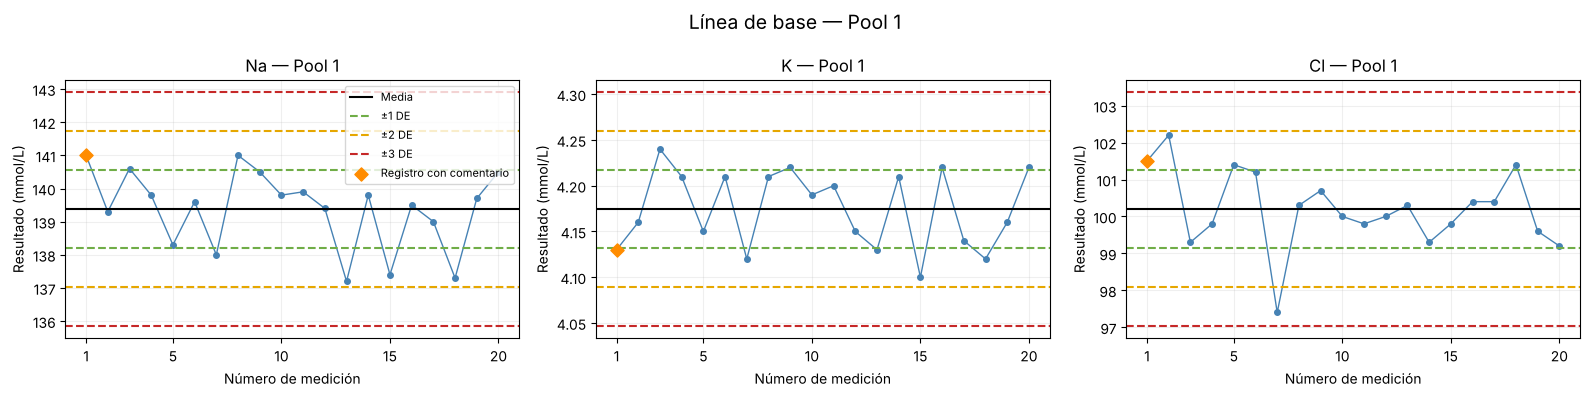

,analito,numero_medicion,fecha,valor,comentario
0,Na,1,2024-08-26,141.00,Pool nuevo
398,K,1,2024-08-26,4.13,Pool nuevo
794,Cl,1,2024-08-26,101.50,Pool nuevo


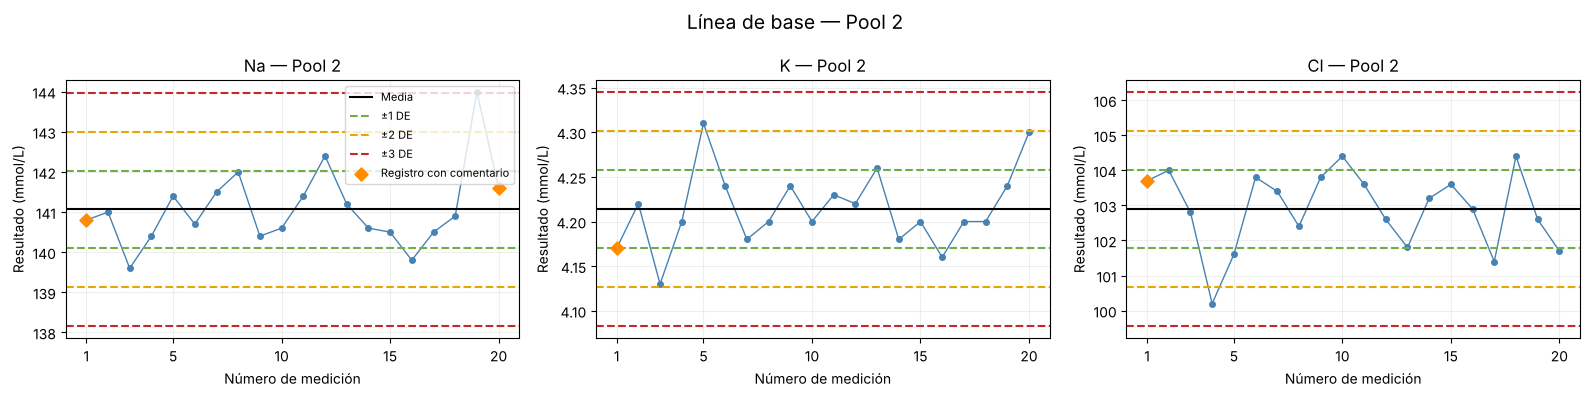

,analito,numero_medicion,fecha,valor,comentario
20,Na,1,2024-10-31,140.80,Pool nuevo
39,Na,20,2024-12-06,141.60,Kit nuevo diestro
418,K,1,2024-10-31,4.17,Pool nuevo
814,Cl,1,2024-10-31,103.70,Pool nuevo


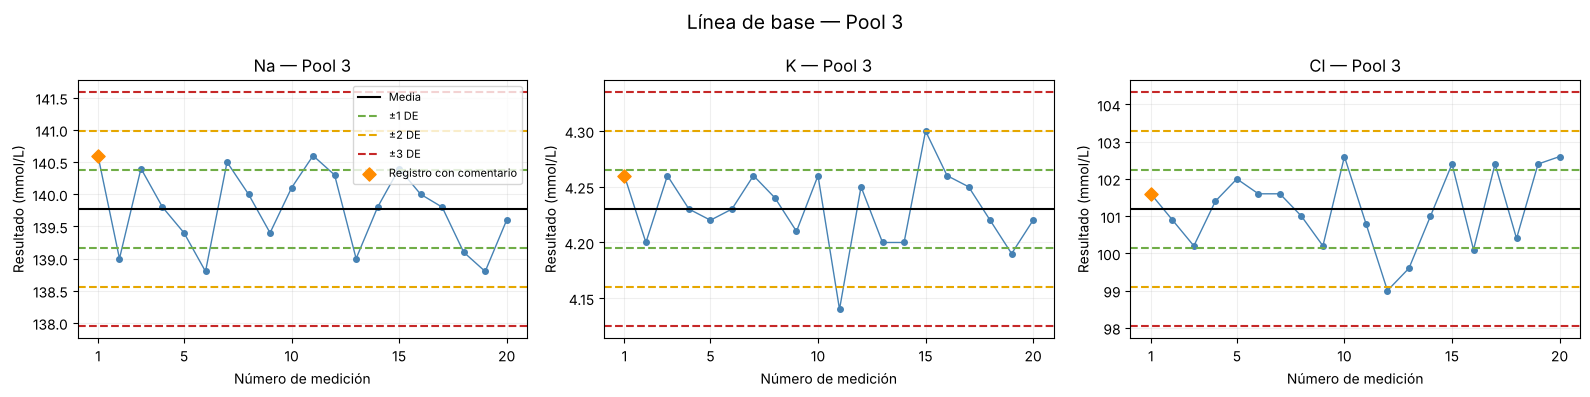

,analito,numero_medicion,fecha,valor,comentario
62,Na,1,2025-01-14,140.60,Pool nuevo
460,K,1,2025-01-14,4.26,Pool nuevo
858,Cl,1,2025-01-14,101.60,Pool nuevo


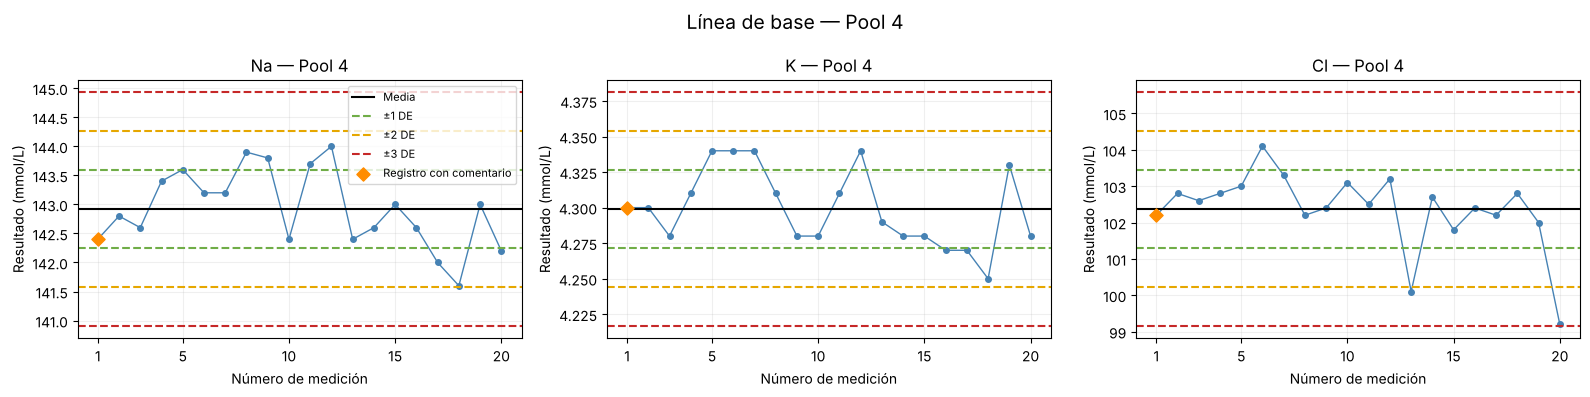

,analito,numero_medicion,fecha,valor,comentario
115,Na,1,2025-04-22,142.4,Pool nuevo
513,K,1,2025-04-22,4.3,Pool nuevo
911,Cl,1,2025-04-22,102.2,Pool nuevo


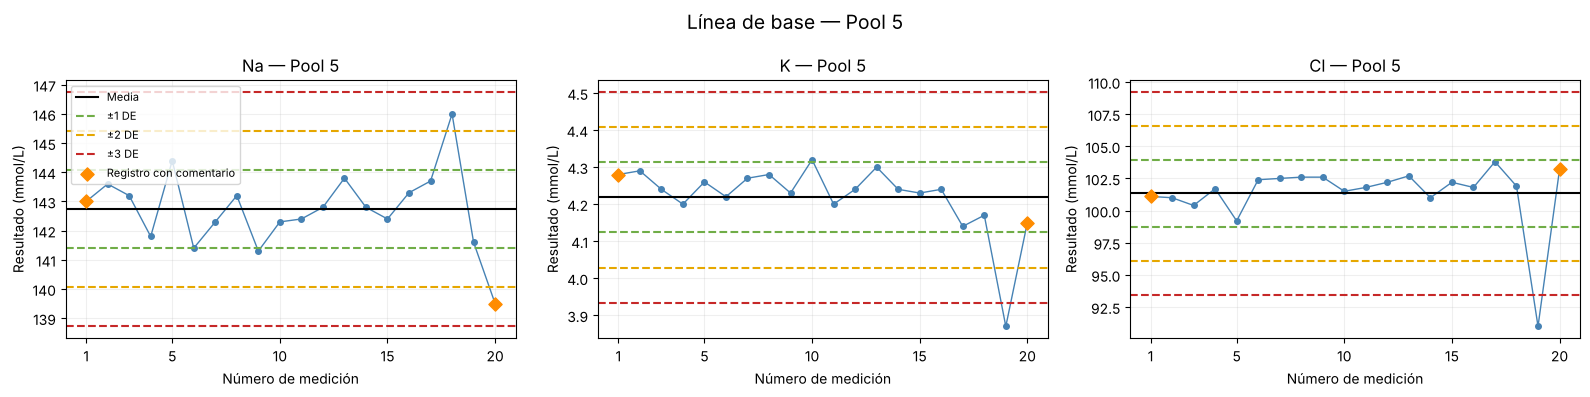

,analito,numero_medicion,fecha,valor,comentario
149,Na,1,2025-06-12,143.00,Pool nuevo
168,Na,20,2025-08-04,139.50,Cambio de electrodos
547,K,1,2025-06-12,4.28,Pool nuevo
566,K,20,2025-08-04,4.15,Cambio de electrodos
944,Cl,1,2025-06-12,101.10,Pool nuevo
963,Cl,20,2025-08-04,103.20,Cambio de electrodos


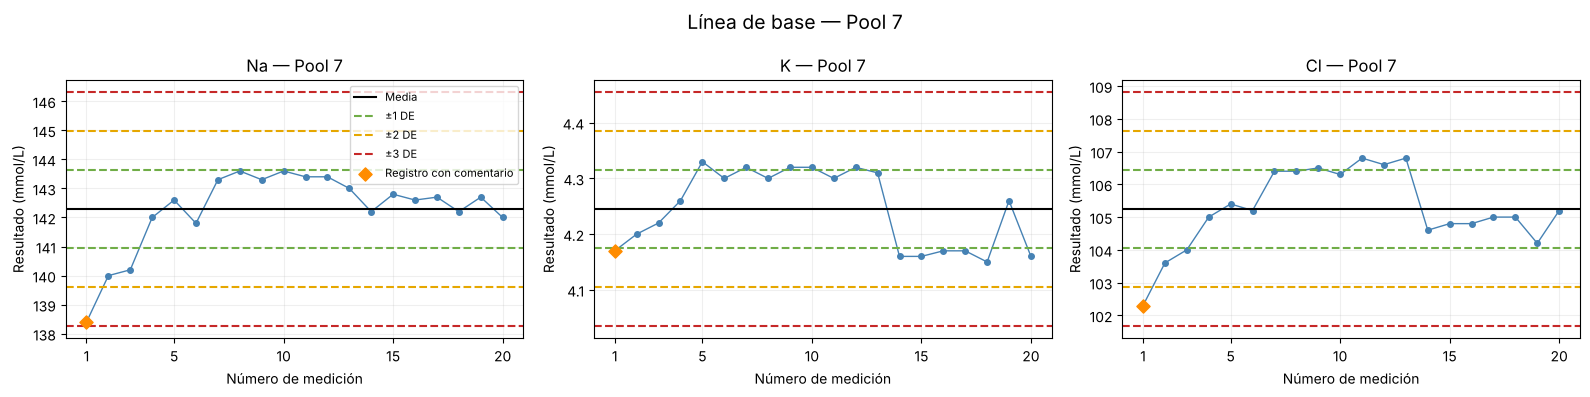

,analito,numero_medicion,fecha,valor,comentario
180,Na,1,2025-08-19,138.40,Pool nuevo
578,K,1,2025-08-19,4.17,Pool nuevo
975,Cl,1,2025-08-19,102.30,Pool nuevo


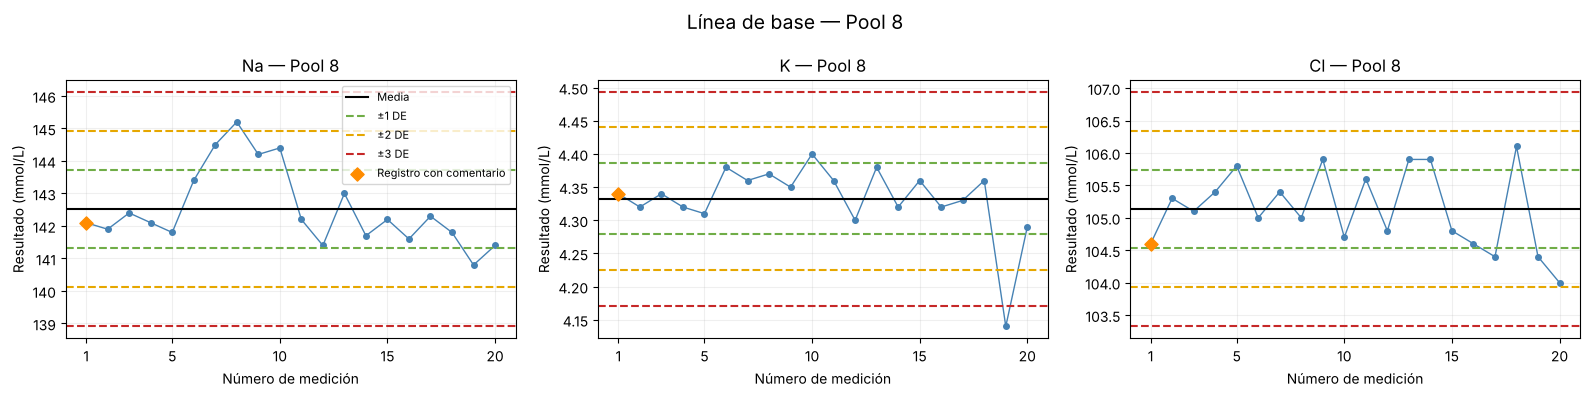

,analito,numero_medicion,fecha,valor,comentario
249,Na,1,2025-11-27,142.10,Pool nuevo
647,K,1,2025-11-27,4.34,Pool nuevo
1044,Cl,1,2025-11-27,104.60,Pool nuevo


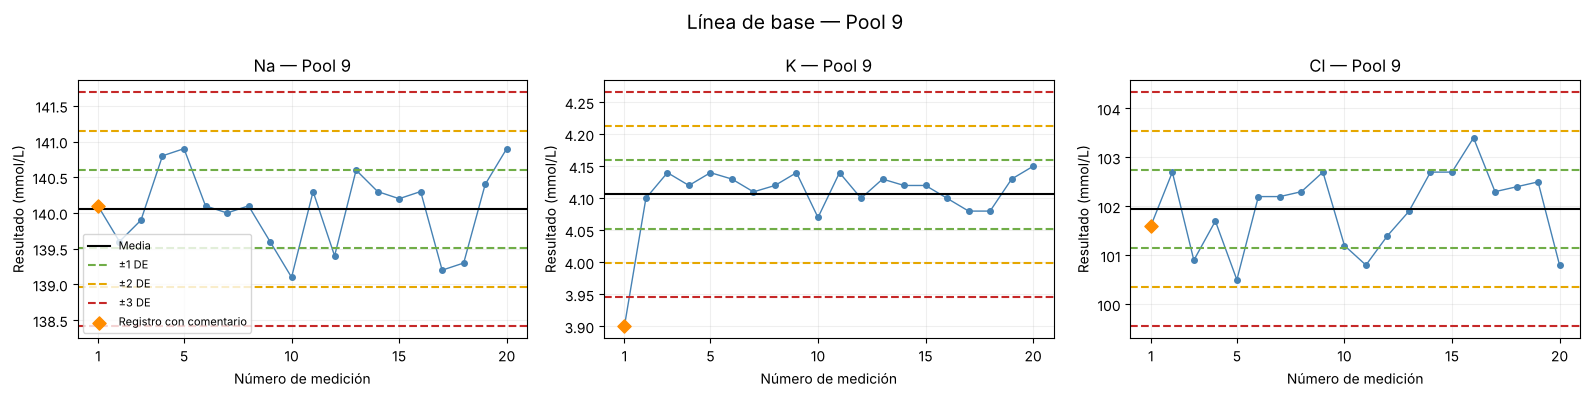

,analito,numero_medicion,fecha,valor,comentario
313,Na,1,2026-04-06,140.1,Pool nuevo
710,K,1,2026-04-06,3.9,Pool nuevo
1108,Cl,1,2026-04-06,101.6,Pool nuevo


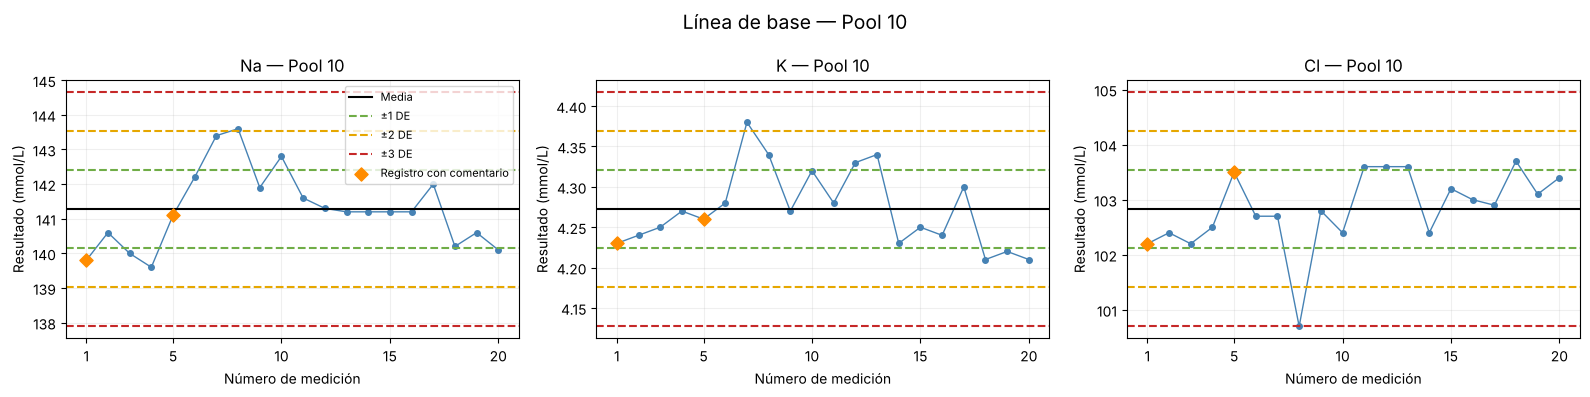

,analito,numero_medicion,fecha,valor,comentario
338,Na,1,2026-05-15,139.80,Pool nuevo
342,Na,5,2026-05-21,141.10,Kit nuevo diestro
735,K,1,2026-05-15,4.23,Pool nuevo
739,K,5,2026-05-21,4.26,Kit nuevo diestro
1133,Cl,1,2026-05-15,102.20,Pool nuevo
1137,Cl,5,2026-05-21,103.50,Kit nuevo diestro


In [18]:
pools_base = sorted(df_base["pool_id"].unique())

for pool in pools_base:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    for ax, analito in zip(axes, orden_analitos):
        datos = (
            df_base.loc[
                (df_base["pool_id"] == pool) &
                (df_base["analito"] == analito)
            ]
            .sort_values("numero_medicion")
        )

        parametros = parametros_base.loc[
            (parametros_base["pool_id"] == pool) &
            (parametros_base["analito"] == analito)
        ].iloc[0]

        media = parametros["media"]
        de = parametros["DE"]

        # Secuencia de mediciones
        ax.plot(
            datos["numero_medicion"],
            datos["valor"],
            marker="o",
            markersize=4,
            linewidth=1,
            color="steelblue"
        )

        # Media y límites descriptivos
        ax.axhline(media, color="black", label="Media")

        for nivel, color in zip(
            [1, 2, 3], ["#70ad47", "#e6a700", "#c62828"]
        ):
            ax.axhline(
                media + nivel * de,
                color=color,
                linestyle="--",
                label=f"±{nivel} DE"
            )
            ax.axhline(
                media - nivel * de,
                color=color,
                linestyle="--"
            )

        # Identificar mediciones con comentarios
        con_comentario = (
            datos["comentario"]
            .fillna("")
            .astype(str)
            .str.strip()
            .ne("")
        )

        eventos = datos.loc[con_comentario]

        ax.scatter(
            eventos["numero_medicion"],
            eventos["valor"],
            color="darkorange",
            marker="D",
            s=45,
            zorder=5,
            label="Registro con comentario"
        )

        ax.set_title(f"{analito} — Pool {pool}")
        ax.set_xlabel("Número de medición")
        ax.set_ylabel("Resultado (mmol/L)")
        ax.set_xticks([1, 5, 10, 15, 20])
        ax.grid(alpha=0.2)

    axes[0].legend(fontsize=8)
    fig.suptitle(f"Línea de base — Pool {pool}", fontsize=14)
    plt.tight_layout()
    plt.show()

    # Mostrar el detalle de los comentarios del pool
    comentarios_pool = df_base.loc[
        (df_base["pool_id"] == pool) &
        df_base["comentario"].fillna("").astype(str).str.strip().ne(""),
        ["analito", "numero_medicion", "fecha", "valor", "comentario"]
    ]

    display(comentarios_pool)

En el pool 5 se identifica una caída marcada de K y Cl en la
medición 19, por debajo del límite descriptivo de −3 DE.
Este hallazgo motiva una revisión de los registros y del contexto
operativo antes de adoptar sus parámetros como referencia.

Los límites se calcularon con las mismas mediciones representadas,
por lo que esta revisión es descriptiva.

### 8.3. Revisión de hallazgos por pool

Se examinan los hallazgos identificados en los gráficos, siguiendo
el orden de los pools y considerando los registros originales
y el contexto operativo.

#### 8.3.1. Pool 1

In [19]:
# Revisar el valor bajo de Cl y su contexto en el pool 1
display(
    df_base.loc[
        (df_base["pool_id"] == 1) &
        df_base["numero_medicion"].between(5, 9),
        [
            "analito", "numero_medicion", "fecha", "hora",
            "valor", "comentario", "pagina_origen", "fila_excel"
        ]
    ].sort_values(["numero_medicion", "analito"])
)

,analito,numero_medicion,fecha,hora,valor,comentario,pagina_origen,fila_excel
4,Na,5,2024-08-30,10:14:14,138.30,NaN,LIBRO 2 — PAG 1,7
402,K,5,2024-08-30,11:59:48,4.15,NaN,LIBRO 1 — PAG 1,7
798,Cl,5,2024-08-30,12:07:47,101.40,NaN,LIBRO 3 — PAG 1,7
5,Na,6,2024-09-02,10:14:28,139.60,NaN,LIBRO 2 — PAG 1,8
403,K,6,2024-09-02,12:00:01,4.21,NaN,LIBRO 1 — PAG 1,8
799,Cl,6,2024-09-02,12:08:50,101.20,NaN,LIBRO 3 — PAG 1,8
6,Na,7,2024-09-03,10:14:44,138.00,NaN,LIBRO 2 — PAG 1,9
404,K,7,2024-09-03,12:00:18,4.12,NaN,LIBRO 1 — PAG 1,9
800,Cl,7,2024-09-03,12:09:03,97.40,NaN,LIBRO 3 — PAG 1,9
7,Na,8,2024-09-04,10:14:55,141.00,NaN,LIBRO 2 — PAG 1,10


En la medición 7 del pool 1, del 03/09/2024, se observa un descenso
de los tres analitos respecto de la medición anterior, más marcado
en Cl (97,40 mmol/L), que se ubica entre −2 y −3 DE. Los valores
aumentan en la medición siguiente.

El cotejo con el registro original confirmó la correcta transcripción
de los valores. La planilla analizada no contiene comentarios asociados
que permitan establecer la causa del descenso. Se conservan las
20 mediciones sin exclusiones.

El pool 1 se utiliza para caracterizar la línea de base y elaborar
un gráfico descriptivo. No se incluye en la comparación de métodos
porque no dispone de mediciones posteriores de seguimiento.

#### 8.3.2. Pool 2

Se revisa el valor elevado de Na en la medición 19 y las mediciones
próximas, considerando los resultados de K y Cl y los comentarios
registrados.

In [20]:
# Revisar las mediciones finales de la línea de base del pool 2
display(
    df_base.loc[
        (df_base["pool_id"] == 2) &
        df_base["numero_medicion"].between(17, 20),
        [
            "analito", "numero_medicion", "fecha", "hora",
            "valor", "comentario", "pagina_origen", "fila_excel"
        ]
    ].sort_values(["fecha", "analito", "hora"])
)

,analito,numero_medicion,fecha,hora,valor,comentario,pagina_origen,fila_excel
434,K,17,2024-12-02,11:12:00,4.20,NaN,LIBRO 1 — PAG 1,39
830,Cl,17,2024-12-02,11:12:10,101.40,NaN,LIBRO 3 — PAG 1,39
36,Na,17,2024-12-03,11:12:52,140.50,NaN,LIBRO 2 — PAG 1,39
435,K,18,2024-12-03,11:12:47,4.20,NaN,LIBRO 1 — PAG 1,40
831,Cl,18,2024-12-03,11:12:17,104.40,NaN,LIBRO 3 — PAG 1,40
37,Na,18,2024-12-04,09:34:10,140.90,NaN,LIBRO 2 — PAG 1,40
436,K,19,2024-12-04,09:34:17,4.24,NaN,LIBRO 1 — PAG 2,3
833,Cl,19,2024-12-04,09:34:23,102.60,NaN,LIBRO 3 — PAG 2,3
38,Na,19,2024-12-05,10:56:23,144.00,NaN,LIBRO 2 — PAG 2,3
437,K,20,2024-12-05,10:56:32,4.30,NaN,LIBRO 1 — PAG 2,4


In [21]:
# Comparar la cantidad de registros por fecha en todo el pool 2
conteos_pool2 = pd.crosstab(
    df.loc[df["pool_id"] == 2, "fecha"],
    df.loc[df["pool_id"] == 2, "analito"]
).reindex(columns=orden_analitos, fill_value=0)

display(
    conteos_pool2.loc[
        conteos_pool2.nunique(axis=1) > 1
    ]
)

analito,Na,K,Cl
fecha,,,
2024-11-12,0,1,1
2025-01-14,1,0,1


In [22]:
display(
    df.loc[
        df["fecha"] == pd.Timestamp("2025-01-14"),
        ["fecha", "hora", "analito", "valor", "comentario", "pool_id"]
    ].sort_values(["analito", "hora"])
)

,fecha,hora,analito,valor,comentario,pool_id
61,2025-01-14,12:14:57,Na,141.00,NaN,2
62,2025-01-14,12:15:22,Na,140.60,Pool nuevo,3
460,2025-01-14,12:15:05,K,4.26,Pool nuevo,3
857,2025-01-14,12:15:12,Cl,102.80,NaN,2
858,2025-01-14,12:15:35,Cl,101.60,Pool nuevo,3


En la medición 19 de Na del pool 2, del 05/12/2024, se registra
144,00 mmol/L, ligeramente por encima del límite descriptivo
de +3 DE. El cotejo manual con el registro original confirmó
su correcta transcripción. K y Cl no presentan un desvío
equivalente en esa fecha.

El 06/12/2024 se registra un cambio de kit de reactivos para
los tres analitos. Ese día, Na presenta 141,60 mmol/L.
La secuencia temporal no permite atribuir el descenso al
cambio de kit.

La revisión manual confirmó dos resultados no anotados en
el registro original: Na del 12/11/2024 y K del pool anterior
del 14/01/2025. Ambos faltantes se mantienen sin imputación.
El resultado de K registrado con «Pool nuevo» el 14/01/2025
permanece correctamente asignado al pool 3.

La ausencia de Na del 12/11/2024 explica que sus primeras
20 mediciones disponibles finalicen el 06/12/2024, mientras
que las de K y Cl terminan el 05/12/2024. Por ello, la lectura
del día del cambio de kit integra la línea de base de Na
y el seguimiento de K y Cl.

Se conservan todas las mediciones disponibles sin exclusiones adicionales. Este hallazgo se considera en 8.4.

#### 8.3.3. Pool 3

Se revisa el descenso de K en la medición 11 y las mediciones
próximas, considerando los resultados de Na y Cl y los comentarios
registrados.

In [23]:
# Identificar la fecha de la medición 11 de K del pool 3
fecha_revision = df_base.loc[
    (df_base["pool_id"] == 3) &
    (df_base["analito"] == "K") &
    (df_base["numero_medicion"] == 11),
    "fecha"
].iloc[0]

# Seleccionar las fechas próximas dentro de la línea de base de K
fechas_revision = df_base.loc[
    (df_base["pool_id"] == 3) &
    (df_base["analito"] == "K") &
    df_base["numero_medicion"].between(9, 13),
    "fecha"
]

# Mostrar los tres analitos en esas mismas fechas
display(
    df.loc[
        (df["pool_id"] == 3) &
        df["fecha"].isin(fechas_revision),
        [
            "analito", "numero_medicion", "fecha", "hora",
            "valor", "comentario", "pagina_origen", "fila_excel"
        ]
    ].sort_values(["fecha", "analito", "hora"])
)

print("Fecha del descenso de K:", fecha_revision.strftime("%d/%m/%Y"))

,analito,numero_medicion,fecha,hora,valor,comentario,pagina_origen,fila_excel
70,Na,9,2025-01-27,12:05:16,139.40,NaN,LIBRO 2 — PAG 2,35
468,K,9,2025-01-27,12:05:24,4.21,NaN,LIBRO 1 — PAG 2,35
866,Cl,9,2025-01-27,12:05:32,100.20,NaN,LIBRO 3 — PAG 2,36
71,Na,10,2025-01-28,11:40:23,140.10,NaN,LIBRO 2 — PAG 2,36
469,K,10,2025-01-28,11:40:33,4.26,NaN,LIBRO 1 — PAG 2,36
867,Cl,10,2025-01-28,11:40:39,102.60,NaN,LIBRO 3 — PAG 2,37
72,Na,11,2025-01-29,12:16:06,140.60,NaN,LIBRO 2 — PAG 2,37
470,K,11,2025-01-29,12:16:13,4.14,NaN,LIBRO 1 — PAG 2,37
868,Cl,11,2025-01-29,12:16:19,100.80,NaN,LIBRO 3 — PAG 2,38
73,Na,12,2025-01-30,11:31:06,140.30,NaN,LIBRO 2 — PAG 2,38


Fecha del descenso de K: 29/01/2025


En la medición 11 del pool 3, del 29/01/2025, K presenta
4,14 mmol/L, entre −2 y −3 DE, y aumenta a 4,25 mmol/L en
la medición siguiente. Na y Cl no presentan un descenso
equivalente en esa fecha.

El 30/01/2025, Cl registra 99,00 mmol/L, ligeramente por debajo
de −2 DE. El cotejo con los registros originales confirmó
la correcta transcripción de ambos valores.

La planilla analizada no contiene comentarios asociados que permitan establecer la causa de estas variaciones. Se conservan las 20 mediciones de cada analito sin exclusiones. Estos hallazgos se consideran en 8.4.

#### 8.3.4. Pool 4

Se revisa el valor bajo de Cl en la medición 20 y el tramo final
de la línea de base, considerando los resultados de los tres
analitos en las mismas fechas.

In [24]:
# Seleccionar las fechas finales de la línea de base de Cl
fechas_revision = df_base.loc[
    (df_base["pool_id"] == 4) &
    (df_base["analito"] == "Cl") &
    df_base["numero_medicion"].between(16, 20),
    "fecha"
]

# Mostrar los tres analitos en esas fechas
display(
    df.loc[
        (df["pool_id"] == 4) &
        df["fecha"].isin(fechas_revision),
        [
            "analito", "numero_medicion", "fecha", "hora",
            "valor", "comentario", "pagina_origen", "fila_excel"
        ]
    ].sort_values(["fecha", "analito", "hora"])
)

,analito,numero_medicion,fecha,hora,valor,comentario,pagina_origen,fila_excel
130,Na,16,2025-05-15,10:08:40,142.60,NaN,LIBRO 2 — PAG 4,13
528,K,16,2025-05-15,10:08:54,4.27,NaN,LIBRO 1 — PAG 4,13
926,Cl,16,2025-05-15,10:09:00,102.40,NaN,LIBRO 3 — PAG 4,14
131,Na,17,2025-05-16,12:13:30,142.00,NaN,LIBRO 2 — PAG 4,14
529,K,17,2025-05-16,12:13:36,4.27,NaN,LIBRO 1 — PAG 4,14
927,Cl,17,2025-05-16,12:13:42,102.20,NaN,LIBRO 3 — PAG 4,15
132,Na,18,2025-05-19,12:47:12,141.60,NaN,LIBRO 2 — PAG 4,15
530,K,18,2025-05-19,12:47:19,4.25,NaN,LIBRO 1 — PAG 4,15
928,Cl,18,2025-05-19,12:47:25,102.80,NaN,LIBRO 3 — PAG 4,16
133,Na,19,2025-05-20,11:47:42,143.00,NaN,LIBRO 2 — PAG 4,16


En el tramo final de la línea de base del pool 4, Na registra
141,60 mmol/L el 19/05/2025, cercano a −2 DE, y Cl presenta
99,20 mmol/L el 21/05/2025, entre −2 y −3 DE.

Los descensos más marcados ocurren en fechas diferentes. El
21/05/2025, Na y K no presentan una caída de magnitud equivalente
a la de Cl.

El cotejo con los registros originales confirmó la correcta
transcripción de ambos valores. La planilla analizada no contiene
comentarios asociados que permitan establecer su causa.
Se conservan las 20 mediciones de cada analito sin exclusiones.

La evolución posterior de Cl se revisará en el seguimiento,
ya que el valor bajo corresponde a la última medición de
la línea de base.

#### 8.3.5. Pool 5

In [25]:
# Revisar el cierre de la línea de base del pool 5
display(
    df_base.loc[
        (df_base["pool_id"] == 5) &
        (df_base["numero_medicion"] >= 16),
        [
            "analito", "numero_medicion", "fecha", "hora",
            "valor", "comentario", "pagina_origen", "fila_excel"
        ]
    ].sort_values(["analito", "numero_medicion"])
)

,analito,numero_medicion,fecha,hora,valor,comentario,pagina_origen,fila_excel
164,Na,16,2025-07-08,13:31:10,143.30,NaN,LIBRO 2 — PAG 5,6
165,Na,17,2025-07-10,12:15:01,143.70,NaN,LIBRO 2 — PAG 5,7
166,Na,18,2025-07-11,11:24:20,146.00,NaN,LIBRO 2 — PAG 5,8
167,Na,19,2025-07-15,10:47:51,141.60,NaN,LIBRO 2 — PAG 5,9
168,Na,20,2025-08-04,10:54:58,139.50,Cambio de electrodos,LIBRO 2 — PAG 5,10
562,K,16,2025-07-08,13:31:18,4.24,NaN,LIBRO 1 — PAG 5,6
563,K,17,2025-07-10,12:15:09,4.14,NaN,LIBRO 1 — PAG 5,7
564,K,18,2025-07-11,11:24:27,4.17,NaN,LIBRO 1 — PAG 5,8
565,K,19,2025-07-15,10:48:08,3.87,NaN,LIBRO 1 — PAG 5,9
566,K,20,2025-08-04,10:55:21,4.15,Cambio de electrodos,LIBRO 1 — PAG 5,10


In [26]:
display(
    df.loc[
        (df["fecha"] > "2025-07-15") &
        (df["fecha"] < "2025-08-04")
    ].sort_values(["fecha", "analito"])
)

,fecha,hora,valor,comentario,analito,hoja_origen,pagina_origen,fila_excel,pool_id,numero_medicion,etapa


El 15/07/2025, en la medición 19 del pool 5, se observa un descenso
de los tres analitos respecto de la medición anterior: Na = 141,60,
K = 3,87 y Cl = 91,00 mmol/L. La caída es más marcada en K y Cl,
que se ubican por debajo de −3 DE en los gráficos descriptivos.

El cotejo con los registros originales confirmó la correcta
transcripción de los tres valores. La planilla analizada no contiene
comentarios asociados que permitan establecer la causa del descenso.

La ausencia de registros entre esa fecha y el 04/08/2025 corresponde
al cierre del laboratorio por vacaciones invernales, según lo
informado por la directora técnica. La medición del 04/08/2025
se realizó después del cambio de electrodos utilizando el mismo
pool: Na = 139,50, K = 4,15 y Cl = 103,20 mmol/L.

Se conservan todos los registros. Este hallazgo se considera en 8.4.

#### 8.3.6. Pool 6

El pool 6 cuenta con 10 mediciones por analito, registradas entre
el 04/08/2025 y el 18/08/2025. No alcanza las 20 mediciones iniciales
establecidas para calcular la línea de base.

Sus registros se conservan por trazabilidad, pero no se utilizan
para establecer parámetros de referencia ni comparar los métodos
de detección de desvíos.

#### 8.3.7. Pool 7

Se revisan los cambios de nivel observados durante las primeras
20 mediciones, considerando su secuencia temporal y los comentarios
registrados.

In [27]:
# Mostrar la línea de base completa del pool 7
with pd.option_context("display.max_rows", None):
    display(
        df_base.loc[
            df_base["pool_id"] == 7,
            [
                "fecha", "hora", "analito", "numero_medicion",
                "valor", "comentario", "pagina_origen", "fila_excel"
            ]
        ].sort_values(["fecha", "analito", "hora"])
    )

,fecha,hora,analito,numero_medicion,valor,comentario,pagina_origen,fila_excel
180,2025-08-19,12:17:59,Na,1,138.40,Pool nuevo,LIBRO 2 — PAG 5,22
578,2025-08-19,12:18:14,K,1,4.17,Pool nuevo,LIBRO 1 — PAG 5,22
975,2025-08-19,12:18:25,Cl,1,102.30,Pool nuevo,LIBRO 3 — PAG 5,22
181,2025-08-20,09:48:51,Na,2,140.00,NaN,LIBRO 2 — PAG 5,23
579,2025-08-20,09:48:58,K,2,4.20,NaN,LIBRO 1 — PAG 5,23
976,2025-08-20,09:49:06,Cl,2,103.60,NaN,LIBRO 3 — PAG 5,23
182,2025-08-21,11:59:00,Na,3,140.20,NaN,LIBRO 2 — PAG 5,24
580,2025-08-21,11:59:07,K,3,4.22,NaN,LIBRO 1 — PAG 5,24
977,2025-08-21,11:59:14,Cl,3,104.00,NaN,LIBRO 3 — PAG 5,24
183,2025-08-22,12:14:58,Na,4,142.00,NaN,LIBRO 2 — PAG 5,25


En el pool 7 se observa un ascenso inicial de los tres analitos,
seguido de un tramo relativamente elevado entre las mediciones
7 y 13, del 27/08/2025 al 04/09/2025.

El 05/09/2025, medición 14, descienden los tres analitos,
especialmente K y Cl. Sus resultados pasan de 4,31 a 4,16 mmol/L
y de 106,80 a 104,60 mmol/L, respectivamente, y permanecen
generalmente en un nivel inferior durante las mediciones siguientes.

El cotejo con los registros originales confirmó la correcta
transcripción de los valores. La planilla analizada no contiene
comentarios asociados que permitan establecer la causa de
los cambios de nivel.

Se conservan todas las mediciones. Este hallazgo se considera en 8.4.

#### 8.3.8. Pool 8

Se revisan el tramo elevado de Na entre las mediciones 6–10 y
el descenso de K en la medición 19, considerando los tres
analitos en las mismas fechas.

In [28]:
# Fechas del tramo elevado de Na
fechas_na = df_base.loc[
    (df_base["pool_id"] == 8) &
    (df_base["analito"] == "Na") &
    df_base["numero_medicion"].between(5, 11),
    "fecha"
]

# Fechas próximas al descenso de K
fechas_k = df_base.loc[
    (df_base["pool_id"] == 8) &
    (df_base["analito"] == "K") &
    df_base["numero_medicion"].between(17, 20),
    "fecha"
]

# Reunir las fechas de ambos tramos
fechas_revision = pd.concat([fechas_na, fechas_k]).unique()

# Mostrar los tres analitos en esas fechas
with pd.option_context("display.max_rows", None):
    display(
        df.loc[
            (df["pool_id"] == 8) &
            df["fecha"].isin(fechas_revision),
            [
                "fecha", "hora", "analito", "numero_medicion",
                "valor", "comentario", "pagina_origen", "fila_excel"
            ]
        ].sort_values(["fecha", "analito", "hora"])
    )

,fecha,hora,analito,numero_medicion,valor,comentario,pagina_origen,fila_excel
253,2025-12-04,11:16:57,Na,5,141.80,NaN,LIBRO 2 — PAG 7,13
651,2025-12-04,11:17:06,K,5,4.31,NaN,LIBRO 1 — PAG 7,13
1048,2025-12-04,11:17:11,Cl,5,105.80,NaN,LIBRO 3 — PAG 7,13
254,2025-12-05,09:48:11,Na,6,143.40,NaN,LIBRO 2 — PAG 7,14
652,2025-12-05,09:48:20,K,6,4.38,NaN,LIBRO 1 — PAG 7,14
1049,2025-12-05,09:48:31,Cl,6,105.00,NaN,LIBRO 3 — PAG 7,14
255,2025-12-10,10:38:21,Na,7,144.50,NaN,LIBRO 2 — PAG 7,15
256,2025-12-10,11:56:26,Na,8,145.20,NaN,LIBRO 2 — PAG 7,16
653,2025-12-10,10:38:29,K,7,4.36,NaN,LIBRO 1 — PAG 7,15
654,2025-12-10,11:56:33,K,8,4.37,NaN,LIBRO 1 — PAG 7,16


En el pool 8, Na presenta un tramo elevado entre el 05/12/2025
y el 12/12/2025, con un máximo de 145,20 mmol/L el 10/12.
El 15/12 disminuye a 142,20 mmol/L.

El 05/01/2026, K registra 4,14 mmol/L, por debajo de −3 DE
en el gráfico descriptivo, y aumenta a 4,29 mmol/L el día
siguiente. Na y Cl también disminuyen respecto de la lectura
anterior, aunque permanecen dentro de ±3 DE.

El cotejo con los registros originales confirmó los valores
revisados y la existencia de dos lecturas con horarios diferentes
el 10/12/2025 para los tres analitos. Se conservan ambas lecturas.

Los registros aportados no contienen comentarios asociados que permitan establecer la causa de estas variaciones. Se mantienen las 20 mediciones por analito sin exclusiones. Este hallazgo se considera en 8.4.

#### 8.3.9. Pool 9

Se revisa el valor inicial de K y su evolución en las mediciones
siguientes, considerando los tres analitos en las mismas fechas.

In [29]:
# Seleccionar las fechas de las primeras cinco mediciones de K
fechas_revision = df_base.loc[
    (df_base["pool_id"] == 9) &
    (df_base["analito"] == "K") &
    df_base["numero_medicion"].between(1, 5),
    "fecha"
]

# Mostrar los tres analitos en esas fechas
display(
    df.loc[
        (df["pool_id"] == 9) &
        df["fecha"].isin(fechas_revision),
        [
            "fecha", "hora", "analito", "numero_medicion",
            "valor", "comentario", "pagina_origen", "fila_excel"
        ]
    ].sort_values(["fecha", "analito", "hora"])
)

,fecha,hora,analito,numero_medicion,valor,comentario,pagina_origen,fila_excel
313,2026-04-06,08:17:01,Na,1,140.10,Pool nuevo,LIBRO 2 — PAG 8,32
710,2026-04-06,08:17:45,K,1,3.90,Pool nuevo,LIBRO 1 — PAG 8,31
1108,2026-04-06,08:18:13,Cl,1,101.60,Pool nuevo,LIBRO 3 — PAG 8,32
314,2026-04-07,08:19:00,Na,2,139.60,NaN,LIBRO 2 — PAG 8,33
711,2026-04-07,08:19:08,K,2,4.10,NaN,LIBRO 1 — PAG 8,32
1109,2026-04-07,08:19:19,Cl,2,102.70,NaN,LIBRO 3 — PAG 8,33
315,2026-04-08,11:11:35,Na,3,139.90,NaN,LIBRO 2 — PAG 8,34
712,2026-04-08,11:12:18,K,3,4.14,NaN,LIBRO 1 — PAG 8,33
1110,2026-04-08,11:12:33,Cl,3,100.90,NaN,LIBRO 3 — PAG 8,34
316,2026-04-09,11:11:45,Na,4,140.80,NaN,LIBRO 2 — PAG 8,35


La primera medición de K del pool 9, del 06/04/2026, presenta
3,90 mmol/L, por debajo de −3 DE en el gráfico descriptivo.
En las cuatro mediciones siguientes, los resultados se sitúan
entre 4,10 y 4,14 mmol/L. Na y Cl no presentan un valor inicial
igualmente alejado de sus respectivas medias.

El cotejo con el registro original confirmó la correcta transcripción
del valor de K. La anotación «Pool nuevo» identifica el inicio
del pool, pero no permite establecer la causa del resultado bajo.

Se conservan las 20 mediciones por analito sin exclusiones. Este hallazgo se considera en 8.4.

#### 8.3.10. Pool 10

Se revisan las variaciones iniciales de Na, el cambio de kit
registrado en la medición 5 y el valor bajo de Cl en la medición 8,
considerando los tres analitos en las mismas fechas.

In [30]:
# Seleccionar las fechas del tramo inicial de Cl
fechas_revision = df_base.loc[
    (df_base["pool_id"] == 10) &
    (df_base["analito"] == "Cl") &
    df_base["numero_medicion"].between(1, 10),
    "fecha"
]

# Mostrar los tres analitos en esas fechas
with pd.option_context("display.max_rows", None):
    display(
        df.loc[
            (df["pool_id"] == 10) &
            df["fecha"].isin(fechas_revision),
            [
                "fecha", "hora", "analito", "numero_medicion",
                "valor", "comentario", "pagina_origen", "fila_excel"
            ]
        ].sort_values(["fecha", "analito", "hora"])
    )

,fecha,hora,analito,numero_medicion,valor,comentario,pagina_origen,fila_excel
338,2026-05-15,11:21:06,Na,1,139.80,Pool nuevo,LIBRO 2 — PAG 9,16
735,2026-05-15,11:21:28,K,1,4.23,Pool nuevo,LIBRO 1 — PAG 9,15
1133,2026-05-15,11:23:10,Cl,1,102.20,Pool nuevo,LIBRO 3 — PAG 9,16
339,2026-05-18,11:22:36,Na,2,140.60,NaN,LIBRO 2 — PAG 9,17
736,2026-05-18,11:21:41,K,2,4.24,NaN,LIBRO 1 — PAG 9,16
1134,2026-05-18,11:23:22,Cl,2,102.40,NaN,LIBRO 3 — PAG 9,17
340,2026-05-19,11:01:30,Na,3,140.00,NaN,LIBRO 2 — PAG 9,18
737,2026-05-19,11:01:36,K,3,4.25,NaN,LIBRO 1 — PAG 9,17
1135,2026-05-19,11:01:43,Cl,3,102.20,NaN,LIBRO 3 — PAG 9,18
341,2026-05-20,10:01:50,Na,4,139.60,NaN,LIBRO 2 — PAG 9,19


En el pool 10, las primeras cuatro mediciones de Na se sitúan
entre 139,60 y 140,60 mmol/L. El 21/05/2026, medición 5,
se registra un cambio de kit de reactivos para los tres analitos.
Posteriormente, Na alcanza 143,40 y 143,60 mmol/L el 26 y 27/05,
y K presenta 4,38 mmol/L el 26/05.

El 27/05/2026, medición 8, Cl registra 100,70 mmol/L, próximo
al límite descriptivo de −3 DE, y aumenta a 102,80 mmol/L en
la medición siguiente. Na y K no muestran un descenso coincidente.

El cotejo con los registros originales confirmó la correcta
transcripción de los valores revisados. La secuencia temporal
no permite atribuir estas variaciones al cambio de kit.

Se conservan las 20 mediciones por analito sin exclusiones. Este hallazgo se considera en 8.4.

#### 8.3.11. Pool 11

El pool 11 cuenta con 9 mediciones por analito, registradas entre
el 19/08/2026 y el 31/08/2026. No alcanza las 20 mediciones iniciales
establecidas para calcular la línea de base.

Sus registros se conservan por trazabilidad, pero no se utilizan
para establecer parámetros de referencia ni comparar los métodos
de detección de desvíos.

### 8.4. Síntesis y criterios para utilizar las líneas de base

La revisión identificó las siguientes variaciones en las líneas de base:

| Pool | Analito | Hallazgo |
|---|---|---|
| 2 | Na | Valor elevado e inclusión de la lectura del cambio de kit |
| 3 | K y Cl | Valores bajos puntuales |
| 4 | Cl | Valor bajo en la última medición |
| 5 | Na, K y Cl | Descenso en la medición 19 e inclusión de una medición posterior al cambio de electrodos |
| 7 | Na, K y Cl | Dos tramos de distinto nivel |
| 8 | Na y K | Tramo elevado de Na y descenso puntual de K |
| 9 | K | Valor inicial bajo |
| 10 | Na, K y Cl | Variaciones alrededor del cambio de kit |

En todos los casos, el cotejo confirmó la correcta transcripción de los valores, y los registros no documentan una causa que justifique excluirlos. Excluir mediciones solo por su distancia a la media reduciría artificialmente la DE de referencia y aumentaría las señales posteriores.

Por ello, se adoptan las 20 mediciones iniciales de cada pool y analito, sin exclusiones adicionales y con parámetros fijos durante el seguimiento. Estos hallazgos se consideran limitaciones de las referencias al interpretar las señales (15 y 17).

## 9. Aplicación de reglas de Westgard

Se aplican reglas de Westgard a las mediciones de seguimiento, utilizando la media y la desviación estándar muestral calculadas con las primeras 20 mediciones de cada combinación de analito y pool.

### 9.1. Reglas seleccionadas y criterios de aplicación

Se evalúan las siguientes reglas:

| Regla | Criterio |
|---|---|
| **1₂s** | Un resultado fuera de ±2 DE. Advertencia, sin rechazo por sí sola. |
| **1₃s** | Un resultado fuera de ±3 DE. |
| **2₂s** | Dos resultados consecutivos más allá de 2 DE, del mismo lado de la media. |
| **4₁s** | Cuatro resultados consecutivos más allá de 1 DE, del mismo lado de la media. |
| **10x** | Diez resultados consecutivos estrictamente del mismo lado de la media. |

Se excluye R₄s porque se dispone de una medición por corrida; no se aplica entre días.

Las secuencias comienzan en la medición 21, sin incorporar la línea de base. Se consideran consecutivas las mediciones disponibles, aunque existan días sin registros, sin combinar analitos ni pools.

Las reglas se evalúan de forma independiente, sin exigir una advertencia 1₂s previa. La alerta global se define mediante 1₃s, 2₂s, 4₁s o 10x.

### 9.2. Cálculo de las reglas de Westgard para cada analito dentro de cada pool

In [31]:
# Pools seleccionados para el seguimiento
pools_evaluables = [2, 3, 4, 5, 7, 8, 9, 10]

resultados_westgard = []

# Evaluar cada analito dentro de cada pool
for (analito, pool), grupo in (
    df[df["pool_id"].isin(pools_evaluables)]
    .groupby(["analito", "pool_id"], observed=True)
):
    grupo = grupo.sort_values("numero_medicion").copy()

    # Línea de base: primeras 20 mediciones
    base = grupo.loc[
        grupo["numero_medicion"] <= 20, "valor"
    ]

    if len(base) != 20 or base.isna().any():
        raise ValueError(
            f"Revisar línea de base: {analito}, pool {pool}"
        )

    media = base.mean()
    de = base.std(ddof=1)

    if pd.isna(de) or de <= 0:
        raise ValueError(
            f"DE no válida: {analito}, pool {pool}"
        )

    # Seguimiento: mediciones desde la número 21
    seguimiento = grupo.loc[
        grupo["numero_medicion"] > 20
    ].copy()

    if seguimiento["valor"].isna().any():
        raise ValueError(
            f"Hay valores faltantes: {analito}, pool {pool}"
        )

    # Desviación respecto de la media, expresada en DE
    seguimiento["media_base"] = media
    seguimiento["de_base"] = de
    seguimiento["z"] = (
        seguimiento["valor"] - media
    ) / de

    z = seguimiento["z"]

    # 1₂s: advertencia
    seguimiento["advertencia_1_2s"] = z.abs() > 2

    # 1₃s: un resultado fuera de ±3 DE
    seguimiento["regla_1_3s"] = z.abs() > 3

    # 2₂s: dos resultados consecutivos más allá de
    # 2 DE, del mismo lado de la media
    seguimiento["regla_2_2s"] = (
        ((z > 2).rolling(2, min_periods=2).sum() == 2)
        | ((z < -2).rolling(2, min_periods=2).sum() == 2)
    )

    # 4₁s: cuatro resultados consecutivos más allá de
    # 1 DE, del mismo lado de la media
    seguimiento["regla_4_1s"] = (
        ((z > 1).rolling(4, min_periods=4).sum() == 4)
        | ((z < -1).rolling(4, min_periods=4).sum() == 4)
    )

    # 10x: diez resultados consecutivos
    # estrictamente del mismo lado de la media
    seguimiento["regla_10x"] = (
        ((z > 0).rolling(10, min_periods=10).sum() == 10)
        | ((z < 0).rolling(10, min_periods=10).sum() == 10)
    )

    # Alerta global: no incluye la advertencia 1₂s
    reglas_alerta = [
        "regla_1_3s",
        "regla_2_2s",
        "regla_4_1s",
        "regla_10x"
    ]

    seguimiento["alerta_westgard"] = (
        seguimiento[reglas_alerta].any(axis=1)
    )

    resultados_westgard.append(seguimiento)

# Reunir todos los resultados de seguimiento
df_westgard = pd.concat(
    resultados_westgard,
    ignore_index=True
)

# Mostrar las primeras 15 filas
columnas_mostrar = [
    "fecha",
    "analito",
    "pool_id",
    "numero_medicion",
    "valor",
    "z",
    "advertencia_1_2s",
    "regla_1_3s",
    "regla_2_2s",
    "regla_4_1s",
    "regla_10x",
    "alerta_westgard"
]

display(df_westgard[columnas_mostrar].head(15))

,fecha,analito,pool_id,numero_medicion,valor,z,advertencia_1_2s,regla_1_3s,regla_2_2s,regla_4_1s,regla_10x,alerta_westgard
0,2024-12-09,Na,2,21,142.3,1.271476,False,False,False,False,False,False
1,2024-12-10,Na,2,22,142.4,1.374429,False,False,False,False,False,False
2,2024-12-11,Na,2,23,141.0,-0.066920,False,False,False,False,False,False
3,2024-12-12,Na,2,24,141.6,0.550801,False,False,False,False,False,False
4,2024-12-13,Na,2,25,141.6,0.550801,False,False,False,False,False,False
5,2024-12-16,Na,2,26,144.4,3.433500,True,True,False,False,False,True
6,2024-12-17,Na,2,27,144.4,3.433500,True,True,True,False,False,True
7,2024-12-17,Na,2,28,141.2,0.138987,False,False,False,False,False,False
8,2024-12-18,Na,2,29,140.8,-0.272827,False,False,False,False,False,False
9,2024-12-19,Na,2,30,139.9,-1.199408,False,False,False,False,False,False


### 9.3. Resumen de advertencias y alertas

In [32]:
resumen_westgard = (
    df_westgard
    .groupby(["analito", "pool_id"], observed=True)
    .agg(
        n_seguimiento=("valor", "size"),
        advertencias_1_2s=("advertencia_1_2s", "sum"),
        alertas_1_3s=("regla_1_3s", "sum"),
        alertas_2_2s=("regla_2_2s", "sum"),
        alertas_4_1s=("regla_4_1s", "sum"),
        alertas_10x=("regla_10x", "sum"),
        registros_con_alerta=("alerta_westgard", "sum")
    )
    .reset_index()
)

resumen_westgard["porcentaje_con_alerta"] = (
    resumen_westgard["registros_con_alerta"]
    / resumen_westgard["n_seguimiento"]
    * 100
)

with pd.option_context("display.max_rows", None):
    display(
        resumen_westgard.style.format({
            "porcentaje_con_alerta": "{:.2f}"
        })
    )

,analito,pool_id,n_seguimiento,advertencias_1_2s,alertas_1_3s,alertas_2_2s,alertas_4_1s,alertas_10x,registros_con_alerta,porcentaje_con_alerta
0,Na,2,22,3,2,1,0,0,2,9.09
1,Na,3,33,10,4,4,2,0,7,21.21
2,Na,4,14,3,1,1,1,0,3,21.43
3,Na,5,1,1,0,0,0,0,0,0.00
4,Na,7,49,0,0,0,0,20,20,40.82
5,Na,8,44,0,0,0,1,0,1,2.27
6,Na,9,5,0,0,0,0,0,0,0.00
7,Na,10,30,0,0,0,0,0,0,0.00
8,K,2,22,8,2,2,6,7,14,63.64
9,K,3,33,1,0,0,1,0,1,3.03


La mayor proporción de registros con alertas corresponde a K del pool 7 (81,63 %), K del pool 2 (63,64 %) y Na del pool 7 (40,82 %). En el pool 7 predomina la regla 10x, cuya interpretación debe considerar los cambios de nivel observados en su línea de base. En K del pool 2 se activan distintas reglas, correspondientes a valores alejados de la media y secuencias persistentes.

Estos porcentajes representan registros señalados, no errores analíticos confirmados. Una misma secuencia puede generar alertas en varias mediciones y cada medición puede activar más de una regla; por ello, los conteos no representan episodios independientes ni deben sumarse entre reglas.

En Na del pool 5 se registra una advertencia 1₂s, sin alerta global. La ausencia de alertas debe interpretarse considerando la cantidad de mediciones disponibles, especialmente en los pools 5 y 9, con solo una y cinco mediciones de seguimiento por analito, respectivamente.

### 9.4. Detalle de los registros con señales de Westgard

Se presentan las mediciones que activan al menos una regla de alerta,
con las reglas correspondientes y los comentarios registrados.

In [33]:
# Seleccionar registros con al menos una regla de alerta
detalle_westgard = df_westgard.loc[
    df_westgard["alerta_westgard"]
].copy()

# Identificar las reglas activadas en cada registro
nombres_reglas = {
    "regla_1_3s": "1₃s",
    "regla_2_2s": "2₂s",
    "regla_4_1s": "4₁s",
    "regla_10x": "10x"
}

detalle_westgard["reglas_activadas"] = detalle_westgard.apply(
    lambda fila: ", ".join(
        nombre
        for columna, nombre in nombres_reglas.items()
        if fila[columna]
    ),
    axis=1
)

# Ordenar por analito, pool y secuencia de medición
detalle_westgard = detalle_westgard.sort_values(
    ["analito", "pool_id", "numero_medicion"]
)

columnas_detalle = [
    "fecha",
    "analito",
    "pool_id",
    "numero_medicion",
    "valor",
    "z",
    "reglas_activadas",
    "comentario"
]

print(
    "Total de registros con señales:",
    len(detalle_westgard)
)

display(
    detalle_westgard[columnas_detalle].style.format({
        "fecha": lambda fecha: fecha.strftime("%d/%m/%Y"),
        "valor": "{:.2f}",
        "z": "{:.2f}"
    }, na_rep="")
)

Total de registros con señales: 112


,fecha,analito,pool_id,numero_medicion,valor,z,reglas_activadas,comentario
5,16/12/2024,Na,2,26,144.40,3.43,1₃s,
6,17/12/2024,Na,2,27,144.40,3.43,"1₃s, 2₂s",
25,05/03/2025,Na,3,24,141.60,3.01,"1₃s, 2₂s",
26,06/03/2025,Na,3,25,141.60,3.01,"1₃s, 2₂s",
33,17/03/2025,Na,3,32,141.10,2.19,2₂s,
34,18/03/2025,Na,3,33,140.80,1.69,4₁s,
35,19/03/2025,Na,3,34,140.40,1.04,4₁s,
49,10/04/2025,Na,3,48,142.10,3.83,"1₃s, 2₂s",
51,14/04/2025,Na,3,50,141.80,3.34,1₃s,
59,28/05/2025,Na,4,25,141.60,-1.96,4₁s,


En el pool 2, las lecturas de K y Cl del 17/12/2024 anotadas con «Calibro equipo» se acercan a sus respectivas medias, aunque mantienen activa la regla 4₁s por las mediciones previas de la secuencia.

En Na del pool 8, la alerta 4₁s del 16/01/2026 coincide con Kit nuevo de reactivo, sin evidencia suficiente para atribuirla al cambio de reactivo.

## 10. Aplicación de Isolation Forest

Se aplica **Isolation Forest** como método complementario para identificar mediciones atípicas del control interno.

### 10.1. Preparación de los datos

Se utilizan los mismos pools y mediciones de seguimiento evaluados con Westgard. Para cada analito dentro de cada pool, las primeras 20 mediciones se reservan para entrenar el modelo y las posteriores para evaluar sus señales.

Las alertas de Westgard no se utilizan como etiquetas de entrenamiento; se conservan para la comparación posterior.

In [34]:
# Utilizar los mismos pools seleccionados para Westgard
df_if = df.loc[
    df["pool_id"].isin(pools_evaluables)
].copy()

# Separar línea de base y seguimiento
df_if_base = df_if.loc[
    df_if["numero_medicion"] <= 20
].copy()

df_if_seguimiento = df_if.loc[
    df_if["numero_medicion"] > 20
].copy()

# Resumir la cantidad de mediciones por analito y pool
resumen_if = (
    df_if_base
    .groupby(["analito", "pool_id"], observed=True)
    .size()
    .rename("n_base")
    .to_frame()
    .join(
        df_if_seguimiento
        .groupby(["analito", "pool_id"], observed=True)
        .size()
        .rename("n_seguimiento"),
        how="outer"
    )
    .fillna(0)
    .astype(int)
    .reset_index()
)

print("Mediciones de línea de base:", len(df_if_base))
print("Mediciones de seguimiento:", len(df_if_seguimiento))

display(resumen_if)

Mediciones de línea de base: 480
Mediciones de seguimiento: 592


,analito,pool_id,n_base,n_seguimiento
0,Na,2,20,22
1,Na,3,20,33
2,Na,4,20,14
3,Na,5,20,1
4,Na,7,20,49
5,Na,8,20,44
6,Na,9,20,5
7,Na,10,20,30
8,K,2,20,22
9,K,3,20,33


### 10.2. Definición y configuración del modelo

Se utiliza el valor del control como única variable, con 200 árboles, `max_samples="auto"` y `random_state=42` para reproducibilidad. El parámetro `contamination="auto"` aplica el umbral predeterminado del algoritmo, sin fijar una proporción de mediciones atípicas.

Cada modelo se entrena con 20 mediciones y no incorpora el orden temporal, por lo que sus resultados tienen alcance exploratorio.

In [35]:
# Variable utilizada por el modelo
variables_if = ["valor"]

# Configuración común para todos los analitos y pools
parametros_if = {
    "n_estimators": 200,
    "max_samples": "auto",
    "contamination": "auto",
    "random_state": 42
}

print("Variable del modelo:", variables_if[0])
print("Parámetros de Isolation Forest:")

for parametro, valor in parametros_if.items():
    print(f"  {parametro}: {valor}")

Variable del modelo: valor
Parámetros de Isolation Forest:
  n_estimators: 200
  max_samples: auto
  contamination: auto
  random_state: 42


### 10.3. Entrenamiento y evaluación del seguimiento

Se obtiene la clasificación y el puntaje de decisión de cada medición de seguimiento. Una predicción de −1, correspondiente a un puntaje negativo, se registra como señal de Isolation Forest.

In [36]:
modelos_if = {}
resultados_if = []

for (analito, pool), base in df_if_base.groupby(
    ["analito", "pool_id"], observed=True
):
    base = base.sort_values("numero_medicion")

    seguimiento = df_if_seguimiento.loc[
        (df_if_seguimiento["analito"] == analito)
        & (df_if_seguimiento["pool_id"] == pool)
    ].sort_values("numero_medicion").copy()

    # Verificar los datos antes de entrenar
    if len(base) != 20 or base[variables_if].isna().any().any():
        raise ValueError(
            f"Revisar datos de entrenamiento: {analito}, pool {pool}"
        )

    if seguimiento.empty:
        continue

    if seguimiento[variables_if].isna().any().any():
        raise ValueError(
            f"Revisar datos de seguimiento: {analito}, pool {pool}"
        )

    # Entrenar un modelo independiente
    modelo = IsolationForest(**parametros_if)
    modelo.fit(base[variables_if])

    # Evaluar las mediciones posteriores
    seguimiento["prediccion_if"] = modelo.predict(
        seguimiento[variables_if]
    )
    seguimiento["puntaje_if"] = modelo.decision_function(
        seguimiento[variables_if]
    )
    seguimiento["alerta_if"] = (
        seguimiento["prediccion_if"] == -1
    )

    modelos_if[(analito, pool)] = modelo
    resultados_if.append(seguimiento)

# Reunir los resultados
df_resultados_if = pd.concat(
    resultados_if, ignore_index=True
)

print("Modelos entrenados:", len(modelos_if))
print("Mediciones evaluadas:", len(df_resultados_if))
print("Registros con señales:", df_resultados_if["alerta_if"].sum())

display(
    df_resultados_if[[
        "fecha",
        "analito",
        "pool_id",
        "numero_medicion",
        "valor",
        "puntaje_if",
        "alerta_if"
    ]].head(15)
)

Modelos entrenados: 24
Mediciones evaluadas: 592
Registros con señales: 356


,fecha,analito,pool_id,numero_medicion,valor,puntaje_if,alerta_if
0,2024-12-09,Na,2,21,142.3,-0.089832,True
1,2024-12-10,Na,2,22,142.4,-0.108912,True
2,2024-12-11,Na,2,23,141.0,0.065582,False
3,2024-12-12,Na,2,24,141.6,0.030041,False
4,2024-12-13,Na,2,25,141.6,0.030041,False
5,2024-12-16,Na,2,26,144.4,-0.268458,True
6,2024-12-17,Na,2,27,144.4,-0.268458,True
7,2024-12-17,Na,2,28,141.2,0.051959,False
8,2024-12-18,Na,2,29,140.8,0.084944,False
9,2024-12-19,Na,2,30,139.9,-0.081143,True


Se entrenaron 24 modelos y se evaluaron 592 mediciones de seguimiento. Isolation Forest generó señales en 356 registros (60,14 %).

En la salida mostrada de Na del pool 2, los valores de 144,40 mmol/L del 16 y 17/12/2024 presentan el puntaje más negativo. También se señalan otras mediciones, como 142,30 y 139,90 mmol/L, mientras que valores como 141,00 y 141,60 mmol/L no generan señales.

### 10.4. Resumen de señales por analito y pool

Se presenta la cantidad y el porcentaje de mediciones de seguimiento
con señales de Isolation Forest para cada analito dentro de los
ocho pools seleccionados.

In [37]:
resumen_senales_if = (
    df_resultados_if
    .groupby(["analito", "pool_id"], observed=True)
    .agg(
        n_seguimiento=("valor", "size"),
        registros_con_senal=("alerta_if", "sum")
    )
    .reset_index()
)

resumen_senales_if["porcentaje_con_senal"] = (
    resumen_senales_if["registros_con_senal"]
    / resumen_senales_if["n_seguimiento"]
    * 100
)

display(
    resumen_senales_if.style.format({
        "porcentaje_con_senal": "{:.2f}"
    })
)

,analito,pool_id,n_seguimiento,registros_con_senal,porcentaje_con_senal
0,Na,2,22,10,45.45
1,Na,3,33,28,84.85
2,Na,4,14,13,92.86
3,Na,5,1,1,100.00
4,Na,7,49,17,34.69
5,Na,8,44,24,54.55
6,Na,9,5,3,60.00
7,Na,10,30,7,23.33
8,K,2,22,19,86.36
9,K,3,33,17,51.52


Las mayores proporciones de señales, entre los grupos con más de una medición de seguimiento, corresponden a Na y K del pool 4 (92,86 %), K de los pools 2 y 7 (86,36 % y 85,71 %, respectivamente) y Na del pool 3 (84,85 %).

En el pool 9 se señalan 3 de 5 mediciones de Na, ninguna de K y 2 de 5 de Cl. En el pool 5, el 100 % corresponde a una única medición de seguimiento por analito, por lo que debe interpretarse considerando ese tamaño reducido.

### 10.5. Sensibilidad de las señales al umbral

Isolation Forest señaló el 60,14 % de las mediciones de seguimiento. Para explorar la influencia del umbral, se realiza una simulación ilustrativa que compara `contamination="auto"` con `contamination=0.05`.

Se generan 200 conjuntos con 20 mediciones de entrenamiento y 40 de seguimiento, procedentes de la misma distribución normal, con media de 4,25 mmol/L, DE de 0,05 mmol/L y redondeo a dos decimales. No se introducen cambios de nivel ni anomalías deliberadas.



In [38]:
# Simulación: mediciones estables, sin desvíos
rng = np.random.default_rng(0)

proporcion_auto = []
proporcion_005 = []

for repeticion in range(200):
    # 20 mediciones de entrenamiento y 40 de seguimiento
    # del mismo nivel (media 4,25; DE 0,05), con dos decimales
    entrenamiento = np.round(rng.normal(4.25, 0.05, 20), 2).reshape(-1, 1)
    seguimiento = np.round(rng.normal(4.25, 0.05, 40), 2).reshape(-1, 1)

    for contaminacion, lista in [("auto", proporcion_auto),
                                 (0.05, proporcion_005)]:
        modelo = IsolationForest(
            n_estimators=200,
            contamination=contaminacion,
            random_state=42
        ).fit(entrenamiento)
        lista.append((modelo.predict(seguimiento) == -1).mean())

print(f"contamination='auto': {np.mean(proporcion_auto) * 100:.1f} % señalado")
print(f"contamination=0.05:   {np.mean(proporcion_005) * 100:.1f} % señalado")

contamination='auto': 51.0 % señalado
contamination=0.05:   5.3 % señalado


En este escenario simulado, el porcentaje promedio de mediciones señaladas fue del 51,0 % con `contamination="auto"` y del 5,3 % con `contamination=0.05`.

La diferencia muestra la sensibilidad de las señales al umbral bajo estas condiciones. No permite generalizar esas proporciones a otros procesos ni atribuir únicamente al umbral el 60,14 % observado en los datos reales.

Se conserva `contamination="auto"` en la comparación principal. La simulación complementa su interpretación, sin establecer cuál configuración resulta más adecuada para el laboratorio.

## 11. Comparación entre Westgard e Isolation Forest



### 11.1. Coincidencias y diferencias por medición

Cada registro de seguimiento se clasifica según presente señales
de ambos métodos, solo de Westgard, solo de Isolation Forest
o de ninguno.

In [39]:
# Identificar cada medición dentro de su analito y pool
claves = ["analito", "pool_id", "numero_medicion"]

# Reunir los resultados de ambos métodos
df_comparacion = df_westgard.merge(
    df_resultados_if[
        claves + ["puntaje_if", "alerta_if"]
    ],
    on=claves,
    how="outer",
    validate="one_to_one",
    indicator=True
)

# Comprobar que ambos métodos evaluaron los mismos registros
if not df_comparacion["_merge"].eq("both").all():
    raise ValueError(
        "Hay mediciones sin correspondencia entre los métodos."
    )

df_comparacion = df_comparacion.drop(columns="_merge")

# Clasificar las coincidencias y diferencias
df_comparacion["comparacion"] = np.select(
    [
        df_comparacion["alerta_westgard"]
        & df_comparacion["alerta_if"],

        df_comparacion["alerta_westgard"]
        & ~df_comparacion["alerta_if"],

        ~df_comparacion["alerta_westgard"]
        & df_comparacion["alerta_if"]
    ],
    [
        "Ambos métodos",
        "Solo Westgard",
        "Solo Isolation Forest"
    ],
    default="Sin señales"
)

# Ordenar por analito, pool y secuencia de medición
df_comparacion = (
    df_comparacion
    .sort_values(claves)
    .reset_index(drop=True)
)

# Comprobar los totales
print("Mediciones comparadas:", len(df_comparacion))
print(
    "Registros con señales de Westgard:",
    df_comparacion["alerta_westgard"].sum()
)
print(
    "Registros con señales de Isolation Forest:",
    df_comparacion["alerta_if"].sum()
)

columnas_comparacion = [
    "fecha",
    "analito",
    "pool_id",
    "numero_medicion",
    "valor",
    "alerta_westgard",
    "alerta_if",
    "comparacion"
]

# Mostrar todas las mediciones
with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None
):
    display(df_comparacion[columnas_comparacion])

Mediciones comparadas: 592
Registros con señales de Westgard: 112
Registros con señales de Isolation Forest: 356


,fecha,analito,pool_id,numero_medicion,valor,alerta_westgard,alerta_if,comparacion
0,2024-12-09,Na,2,21,142.30,False,True,Solo Isolation Forest
1,2024-12-10,Na,2,22,142.40,False,True,Solo Isolation Forest
2,2024-12-11,Na,2,23,141.00,False,False,Sin señales
3,2024-12-12,Na,2,24,141.60,False,False,Sin señales
4,2024-12-13,Na,2,25,141.60,False,False,Sin señales
5,2024-12-16,Na,2,26,144.40,True,True,Ambos métodos
6,2024-12-17,Na,2,27,144.40,True,True,Ambos métodos
7,2024-12-17,Na,2,28,141.20,False,False,Sin señales
8,2024-12-18,Na,2,29,140.80,False,False,Sin señales
9,2024-12-19,Na,2,30,139.90,False,True,Solo Isolation Forest


De las 592 mediciones comparadas, 86 presentan señales de ambos métodos, 26 solo de Westgard, 270 solo de Isolation Forest y 210 no presentan señales de ninguno.
Esta comparación describe la concordancia entre métodos; no constituye una validación frente a errores confirmados ni permite determinar, por sí sola, cuál tiene mejor desempeño.

### 11.2. Resumen de coincidencias y diferencias por analito y pool

Se agrupan las mediciones en las cuatro categorías de comparación
para facilitar la lectura de los resultados.

In [40]:
# Orden de las categorías de comparación
categorias = [
    "Ambos métodos",
    "Solo Westgard",
    "Solo Isolation Forest",
    "Sin señales"
]

# Contar las mediciones de cada categoría por analito y pool
resumen_comparacion = (
    df_comparacion
    .groupby(
        ["analito", "pool_id", "comparacion"],
        observed=True
    )
    .size()
    .unstack("comparacion", fill_value=0)
    .reindex(columns=categorias, fill_value=0)
)

# Total de mediciones de seguimiento por analito y pool
resumen_comparacion["Total seguimiento"] = (
    resumen_comparacion[categorias].sum(axis=1)
)

resumen_comparacion = resumen_comparacion.reset_index()
resumen_comparacion.columns.name = None

# Verificar que el resumen incluya todas las mediciones
assert (
    resumen_comparacion["Total seguimiento"].sum()
    == len(df_comparacion)
), "Revisar los conteos del resumen."

display(resumen_comparacion)

,analito,pool_id,Ambos métodos,Solo Westgard,Solo Isolation Forest,Sin señales,Total seguimiento
0,Na,2,2,0,8,12,22
1,Na,3,6,1,22,4,33
2,Na,4,3,0,10,1,14
3,Na,5,0,0,1,0,1
4,Na,7,5,15,12,17,49
5,Na,8,1,0,23,20,44
6,Na,9,0,0,3,2,5
7,Na,10,0,0,7,23,30
8,K,2,12,2,7,1,22
9,K,3,1,0,16,16,33


**Isolation Forest** genera señales exclusivas en 23 de las 24 combinaciones de analito y pool; la excepción es K del pool 9. Los mayores conteos corresponden a Cl de los pools 8 y 7, con 27 y 26 registros, respectivamente.

En Na del pool 10, siete mediciones son señaladas únicamente por Isolation Forest y las 23 restantes no presentan señales de ninguno de los métodos.

### 11.3. Registros con señales exclusivas de Westgard

Se identifican las reglas activadas en las mediciones que
Isolation Forest no señala, junto con su desviación respecto
de la media y los comentarios registrados.

In [41]:
# Seleccionar las mediciones señaladas solo por Westgard
solo_westgard = df_comparacion.loc[
    df_comparacion["comparacion"] == "Solo Westgard"
].copy()

# Identificar las reglas activadas
nombres_reglas = {
    "regla_1_3s": "1₃s",
    "regla_2_2s": "2₂s",
    "regla_4_1s": "4₁s",
    "regla_10x": "10x"
}

solo_westgard["reglas_activadas"] = solo_westgard.apply(
    lambda fila: ", ".join(
        nombre
        for columna, nombre in nombres_reglas.items()
        if fila[columna]
    ),
    axis=1
)

solo_westgard = solo_westgard.sort_values(
    ["analito", "pool_id", "numero_medicion"]
)

print("Registros señalados solo por Westgard:", len(solo_westgard))

display(
    solo_westgard[[
        "fecha",
        "analito",
        "pool_id",
        "numero_medicion",
        "valor",
        "z",
        "reglas_activadas",
        "puntaje_if",
        "comentario"
    ]].style.format({
        "fecha": lambda fecha: fecha.strftime("%d/%m/%Y"),
        "valor": "{:.2f}",
        "z": "{:.2f}",
        "puntaje_if": "{:.4f}"
    }, na_rep="")
)

Registros señalados solo por Westgard: 26


,fecha,analito,pool_id,numero_medicion,valor,z,reglas_activadas,puntaje_if,comentario
35,19/03/2025,Na,3,34,140.40,1.04,4₁s,0.0213,
87,09/10/2025,Na,7,38,143.00,0.53,10x,0.0154,
88,13/10/2025,Na,7,39,143.00,0.53,10x,0.0154,
90,15/10/2025,Na,7,41,142.70,0.30,10x,0.0900,
91,16/10/2025,Na,7,42,143.00,0.53,10x,0.0154,
92,17/10/2025,Na,7,43,143.40,0.82,10x,0.0399,
96,23/10/2025,Na,7,47,142.50,0.16,10x,0.0730,
97,24/10/2025,Na,7,48,142.90,0.45,10x,0.0305,
98,27/10/2025,Na,7,49,143.10,0.60,10x,0.0251,
100,29/10/2025,Na,7,51,143.00,0.53,10x,0.0154,


Las 26 mediciones señaladas únicamente por Westgard activan reglas de secuencia: 25 presentan 10x —tres también 4₁s— y una presenta únicamente 4₁s. Ninguna activa 1₃s ni 2₂s.

Todas se encuentran dentro de ±2 DE. Por ejemplo, K del pool 2, con 4,22 mmol/L y z = +0,14, activa 10x por integrar una secuencia de diez mediciones consecutivas del mismo lado de la media.

Estos casos muestran que una medición puede formar parte de una secuencia señalada por Westgard sin resultar atípica para Isolation Forest con la configuración utilizada.

### 11.4. Registros con señales exclusivas de Isolation Forest

Se presentan estas mediciones junto con su desviación respecto
de la media, la advertencia 1₂s y el puntaje de decisión del modelo.

In [42]:
# Seleccionar las mediciones señaladas solo por Isolation Forest
solo_if = df_comparacion.loc[
    df_comparacion["comparacion"] == "Solo Isolation Forest"
].copy()

solo_if = solo_if.sort_values(
    ["analito", "pool_id", "numero_medicion"]
)

# Clasificar la distancia a la media de referencia
solo_if["distancia_media"] = np.where(
    solo_if["z"].abs() > 2,
    "Más allá de ±2 DE",
    "Dentro de ±2 DE"
)

print(
    "Registros señalados solo por Isolation Forest:",
    len(solo_if)
)

# Resumen de la distancia a la media
resumen_distancia_if = (
    solo_if["distancia_media"]
    .value_counts()
    .reindex(
        ["Dentro de ±2 DE", "Más allá de ±2 DE"],
        fill_value=0
    )
    .rename_axis("Distancia a la media")
    .reset_index(name="Cantidad de registros")
)

display(resumen_distancia_if)

# Mostrar todos los registros seleccionados
display(
    solo_if[[
        "fecha",
        "analito",
        "pool_id",
        "numero_medicion",
        "valor",
        "z",
        "advertencia_1_2s",
        "puntaje_if",
        "comentario"
    ]].style.format({
        "fecha": lambda fecha: fecha.strftime("%d/%m/%Y"),
        "valor": "{:.2f}",
        "z": "{:.2f}",
        "puntaje_if": "{:.4f}"
    }, na_rep="")
)

Registros señalados solo por Isolation Forest: 270


,Distancia a la media,Cantidad de registros
0,Dentro de ±2 DE,242
1,Más allá de ±2 DE,28


,fecha,analito,pool_id,numero_medicion,valor,z,advertencia_1_2s,puntaje_if,comentario
0,09/12/2024,Na,2,21,142.30,1.27,False,-0.0898,
1,10/12/2024,Na,2,22,142.40,1.37,False,-0.1089,
9,19/12/2024,Na,2,30,139.90,-1.20,False,-0.0811,
10,20/12/2024,Na,2,31,142.10,1.07,False,-0.0667,
12,26/12/2024,Na,2,33,142.10,1.07,False,-0.0667,
13,27/12/2024,Na,2,34,139.30,-1.82,False,-0.1408,
16,07/01/2025,Na,2,37,140.00,-1.10,False,-0.0492,
19,10/01/2025,Na,2,40,138.40,-2.74,True,-0.1408,
22,26/02/2025,Na,3,21,139.00,-1.27,False,-0.0207,
23,28/02/2025,Na,3,22,139.00,-1.27,False,-0.0207,


De las 270 mediciones señaladas únicamente por Isolation Forest, 242 se encuentran dentro de ±2 DE y 28 superan ese límite. Estas últimas activan la advertencia 1₂s, pero no las reglas que definen la alerta global de Westgard.

También se señalan valores próximos a la media, como K = 4,30 mmol/L del pool 4, con z = +0,04 y un puntaje de decisión ligeramente negativo. Este ejemplo muestra que las señales del modelo no dependen únicamente de la distancia a la media.

## 12. EWMA como referencia adicional

### 12.1. Criterios de aplicación

EWMA (media móvil exponencialmente ponderada) combina la medición actual con el estadístico anterior para explorar cambios sostenidos.

Se aplica por analito y pool, utilizando las mismas medias y desviaciones estándar de referencia. Se establece λ = 0,20: la medición actual aporta el 20 % y el estadístico anterior, el 80 %. El factor L = 3 determina la amplitud de los límites de control.

El cálculo comienza en la primera medición de seguimiento, con un valor inicial igual a la media de la línea de base.

In [43]:
# Parámetros para el cálculo de EWMA
lambda_ewma = 0.20
factor_limites_ewma = 3

print("Peso de la medición actual:", lambda_ewma)
print("Peso del promedio anterior:", 1 - lambda_ewma)
print("Factor para los límites de EWMA:", factor_limites_ewma)

Peso de la medición actual: 0.2
Peso del promedio anterior: 0.8
Factor para los límites de EWMA: 3


### 12.2. Cálculo de EWMA en el seguimiento

Se calcula el estadístico EWMA y sus límites para cada medición.
Los límites consideran la cantidad de mediciones acumuladas desde
el inicio del seguimiento. Se genera una señal cuando EWMA queda
fuera de ellos.

In [44]:
resultados_ewma = []

for (analito, pool), grupo in df_westgard.groupby(
    ["analito", "pool_id"], observed=True
):
    grupo = grupo.sort_values("numero_medicion").copy()

    # Recuperar los parámetros de referencia
    media = grupo["media_base"].iloc[0]
    de = grupo["de_base"].iloc[0]

    # Iniciar EWMA en la media de la línea de base
    ewma_anterior = media
    valores_ewma = []

    for valor in grupo["valor"]:
        ewma_actual = (
            lambda_ewma * valor
            + (1 - lambda_ewma) * ewma_anterior
        )

        valores_ewma.append(ewma_actual)
        ewma_anterior = ewma_actual

    grupo["ewma"] = valores_ewma

    # Número de mediciones acumuladas en el seguimiento
    t = np.arange(1, len(grupo) + 1)

    # Desviación estándar del estadístico EWMA
    de_ewma = de * np.sqrt(
        lambda_ewma / (2 - lambda_ewma)
        * (1 - (1 - lambda_ewma) ** (2 * t))
    )

    # Límites para cada posición de la secuencia
    grupo["limite_inferior_ewma"] = (
        media - factor_limites_ewma * de_ewma
    )
    grupo["limite_superior_ewma"] = (
        media + factor_limites_ewma * de_ewma
    )

    grupo["alerta_ewma"] = (
        (grupo["ewma"] < grupo["limite_inferior_ewma"])
        | (grupo["ewma"] > grupo["limite_superior_ewma"])
    )

    resultados_ewma.append(grupo)

df_ewma = pd.concat(resultados_ewma, ignore_index=True)

print("Mediciones evaluadas:", len(df_ewma))
print("Registros con señales de EWMA:", df_ewma["alerta_ewma"].sum())

# Seleccionar todas las mediciones con señales de EWMA
senales_ewma = df_ewma.loc[
    df_ewma["alerta_ewma"]
].copy()

senales_ewma = senales_ewma.sort_values(
    ["analito", "pool_id", "numero_medicion"]
)

# Identificar el límite superado
senales_ewma["direccion_senal"] = np.where(
    senales_ewma["ewma"]
    > senales_ewma["limite_superior_ewma"],
    "Por encima del límite superior",
    "Por debajo del límite inferior"
)



# Mostrar todas las señales y sus comentarios
display(
    senales_ewma[[
        "fecha",
        "analito",
        "pool_id",
        "numero_medicion",
        "valor",
        "ewma",
        "limite_inferior_ewma",
        "limite_superior_ewma",
        "direccion_senal",
        "comentario"
    ]].style.format({
        "fecha": lambda fecha: fecha.strftime("%d/%m/%Y"),
        "valor": "{:.2f}",
        "ewma": "{:.3f}",
        "limite_inferior_ewma": "{:.3f}",
        "limite_superior_ewma": "{:.3f}"
    }, na_rep="")
)

Mediciones evaluadas: 592
Registros con señales de EWMA: 97


,fecha,analito,pool_id,numero_medicion,valor,ewma,limite_inferior_ewma,limite_superior_ewma,direccion_senal,comentario
5,16/12/2024,Na,2,26,144.40,142.070,140.128,142.002,Por encima del límite superior,
6,17/12/2024,Na,2,27,144.40,142.536,140.115,142.015,Por encima del límite superior,
7,17/12/2024,Na,2,28,141.20,142.269,140.107,142.023,Por encima del límite superior,Calibro equipo
26,06/03/2025,Na,3,25,141.60,140.470,139.196,140.344,Por encima del límite superior,
33,17/03/2025,Na,3,32,141.10,140.391,139.164,140.376,Por encima del límite superior,
34,18/03/2025,Na,3,33,140.80,140.473,139.163,140.377,Por encima del límite superior,
35,19/03/2025,Na,3,34,140.40,140.458,139.163,140.377,Por encima del límite superior,
44,03/04/2025,Na,3,43,141.50,140.510,139.162,140.378,Por encima del límite superior,
48,09/04/2025,Na,3,47,141.20,140.437,139.162,140.378,Por encima del límite superior,
49,10/04/2025,Na,3,48,142.10,140.769,139.162,140.378,Por encima del límite superior,


EWMA señala 97 registros en 11 de las 24 combinaciones de analito y pool. El mayor conteo corresponde a K del pool 7, con 24 señales inferiores distribuidas en distintos tramos entre el 03/10 y el 26/11/2025.

En el pool 2 se registran tres señales superiores de Na, 15 superiores de K y seis inferiores de Cl. Las mediciones con el comentario «Calibro equipo» mantienen señales porque el estadístico incorpora el efecto de los resultados anteriores.

También se identifican señales superiores de Na y K del pool 3; inferiores de Na y K del pool 4 y de Cl del pool 7; e inferiores de K y superiores de Cl del pool 10. Una señal de Cl coincide con el registro de un kit nuevo de reactivos del 14/07/2026, sin que esta coincidencia permita establecer causalidad.
No se generan señales en los pools 5, 8 y 9. Como en Westgard (9.3), varias señales pueden pertenecer a una misma secuencia.

## 13. CUSUM como referencia adicional

### 13.1. Criterios de aplicación

CUSUM acumula las desviaciones respecto de la media de referencia, por separado para ascensos y descensos.

Se utilizarán los valores estandarizados z de cada analito dentro de cada pool, con un valor de referencia k = 0,5 y un umbral h = 5.

Las sumas comienzan en cero al iniciar el seguimiento de cada analito dentro de cada pool. Se genera una señal cuando alguna supera el umbral.

Para este análisis retrospectivo, las sumas no se reinician automáticamente al generar una señal; los registros posteriores pueden corresponder a la continuidad de una misma secuencia.

In [45]:
# Parámetros de CUSUM sobre valores estandarizados
k_cusum = 0.5
h_cusum = 5.0

print("Valor de referencia k:", k_cusum)
print("Umbral de señal h:", h_cusum)

Valor de referencia k: 0.5
Umbral de señal h: 5.0


### 13.2. Cálculo de CUSUM en el seguimiento

Se calculan las sumas acumuladas para ascensos y descensos
y se presentan los registros que superan el umbral establecido.

In [46]:
resultados_cusum = []

for (analito, pool), grupo in df_westgard.groupby(
    ["analito", "pool_id"], observed=True
):
    grupo = grupo.sort_values("numero_medicion").copy()

    # Iniciar las sumas para cada analito dentro de cada pool
    suma_superior = 0.0
    suma_inferior = 0.0

    valores_superiores = []
    valores_inferiores = []

    for z in grupo["z"]:
        # Acumular desviaciones para ascensos y descensos
        suma_superior = max(
            0.0, suma_superior + z - k_cusum
        )
        suma_inferior = max(
            0.0, suma_inferior - z - k_cusum
        )

        valores_superiores.append(suma_superior)
        valores_inferiores.append(suma_inferior)

    grupo["cusum_superior"] = valores_superiores
    grupo["cusum_inferior"] = valores_inferiores

    grupo["senal_cusum_superior"] = (
        grupo["cusum_superior"] > h_cusum
    )
    grupo["senal_cusum_inferior"] = (
        grupo["cusum_inferior"] > h_cusum
    )

    grupo["alerta_cusum"] = (
        grupo["senal_cusum_superior"]
        | grupo["senal_cusum_inferior"]
    )

    resultados_cusum.append(grupo)

# Reunir todas las mediciones evaluadas
df_cusum = pd.concat(resultados_cusum, ignore_index=True)

# Seleccionar todos los registros con señales
senales_cusum = df_cusum.loc[
    df_cusum["alerta_cusum"]
].copy()

senales_cusum["direccion_senal"] = np.select(
    [
        senales_cusum["senal_cusum_superior"]
        & senales_cusum["senal_cusum_inferior"],
        senales_cusum["senal_cusum_superior"],
        senales_cusum["senal_cusum_inferior"]
    ],
    [
        "Ambas sumas superan el umbral",
        "Suma para ascensos supera el umbral",
        "Suma para descensos supera el umbral"
    ],
    default=""
)

senales_cusum = senales_cusum.sort_values(
    ["analito", "pool_id", "numero_medicion"]
)

print("Mediciones evaluadas:", len(df_cusum))
print("Registros con señales de CUSUM:", len(senales_cusum))

display(
    senales_cusum[[
        "fecha",
        "analito",
        "pool_id",
        "numero_medicion",
        "valor",
        "z",
        "cusum_superior",
        "cusum_inferior",
        "direccion_senal",
        "comentario"
    ]].style.format({
        "fecha": lambda fecha: fecha.strftime("%d/%m/%Y"),
        "valor": "{:.2f}",
        "z": "{:.2f}",
        "cusum_superior": "{:.3f}",
        "cusum_inferior": "{:.3f}"
    }, na_rep="")
)

Mediciones evaluadas:

 592
Registros con señales de CUSUM: 182


,fecha,analito,pool_id,numero_medicion,valor,z,cusum_superior,cusum_inferior,direccion_senal,comentario
6,17/12/2024,Na,2,27,144.40,3.43,7.048,0.000,Suma para ascensos supera el umbral,
7,17/12/2024,Na,2,28,141.20,0.14,6.687,0.000,Suma para ascensos supera el umbral,Calibro equipo
8,18/12/2024,Na,2,29,140.80,-0.27,5.914,0.000,Suma para ascensos supera el umbral,
26,06/03/2025,Na,3,25,141.60,3.01,6.873,0.000,Suma para ascensos supera el umbral,
27,07/03/2025,Na,3,26,139.40,-0.61,5.764,0.109,Suma para ascensos supera el umbral,
32,14/03/2025,Na,3,31,141.00,2.02,5.320,0.000,Suma para ascensos supera el umbral,
33,17/03/2025,Na,3,32,141.10,2.19,7.008,0.000,Suma para ascensos supera el umbral,
34,18/03/2025,Na,3,33,140.80,1.69,8.202,0.000,Suma para ascensos supera el umbral,
35,19/03/2025,Na,3,34,140.40,1.04,8.739,0.000,Suma para ascensos supera el umbral,
36,20/03/2025,Na,3,35,139.40,-0.61,7.630,0.109,Suma para ascensos supera el umbral,


CUSUM genera 182 registros con señales, distribuidos en 12 combinaciones de analito y pool. La mayor cantidad corresponde a K del pool 7: 40 mediciones consecutivas, desde el 29/09 hasta el 26/11/2025, con la suma para descensos por encima del umbral. En ese pool también se identifican cinco señales para ascensos en Na y tres para descensos en Cl.

En el pool 2 se registran tres señales para ascensos en Na, 19 en K y ocho para descensos en Cl. En el pool 3, las señales corresponden a ascensos: 25 en Na y 21 en K. En el pool 4 se identifican ocho señales para descensos en Na y nueve en K.

En el pool 10 aparecen 19 señales para descensos en K y 22 para ascensos en Cl. No se generan señales en los pools 5, 8 y 9, ni en las restantes combinaciones de analito y pool.

La persistencia de la suma puede mantener una señal aun cuando la medición actual se aproxima a la media. Por ejemplo, Na del pool 2 conserva una señal el 17/12/2024 con z = +0,14, debido a la acumulación previa. Por ello, como se indicó en 9.3, los registros señalados no representan episodios independientes.

## 14. Comparación conjunta de los métodos

### 14.1. Resumen de señales por analito dentro de cada pool

Se presenta la cantidad de registros señalados por Westgard,
Isolation Forest, EWMA y CUSUM sobre las mismas mediciones
de seguimiento.

In [47]:
claves = ["analito", "pool_id", "numero_medicion"]

# Incorporar EWMA y CUSUM a la comparación existente
df_cuatro_metodos = df_comparacion.copy()

for tabla, columna in [
    (df_ewma, "alerta_ewma"),
    (df_cusum, "alerta_cusum")
]:
    df_cuatro_metodos = df_cuatro_metodos.merge(
        tabla[claves + [columna]],
        on=claves,
        how="outer",
        validate="one_to_one",
        indicator=True
    )

    if not df_cuatro_metodos["_merge"].eq("both").all():
        raise ValueError(
            f"Hay mediciones sin correspondencia para {columna}."
        )

    df_cuatro_metodos = df_cuatro_metodos.drop(
        columns="_merge"
    )

# Resumir las señales por analito y pool
resumen_cuatro_metodos = (
    df_cuatro_metodos
    .groupby(["analito", "pool_id"], observed=True)
    .agg(
        n_seguimiento=("valor", "size"),
        Westgard=("alerta_westgard", "sum"),
        Isolation_Forest=("alerta_if", "sum"),
        EWMA=("alerta_ewma", "sum"),
        CUSUM=("alerta_cusum", "sum")
    )
    .reset_index()
)

print("Mediciones comparadas:", len(df_cuatro_metodos))
display(resumen_cuatro_metodos)

# Cantidad y porcentaje global de registros señalados
total_mediciones = len(df_cuatro_metodos)

resumen_global = (
    resumen_cuatro_metodos[
        ["Westgard", "Isolation_Forest", "EWMA", "CUSUM"]
    ]
    .sum()
    .rename_axis("Metodo")
    .reset_index(name="Registros_con_senal")
)

resumen_global["Mediciones_evaluadas"] = total_mediciones

resumen_global["Porcentaje_con_senal"] = (
    resumen_global["Registros_con_senal"]
    / total_mediciones
    * 100
)

print("Resumen global de señales:")

display(
    resumen_global[
        [
            "Metodo",
            "Mediciones_evaluadas",
            "Registros_con_senal",
            "Porcentaje_con_senal"
        ]
    ].style.format({
        "Porcentaje_con_senal": "{:.2f}%"
    })
)

Mediciones comparadas: 592


,analito,pool_id,n_seguimiento,Westgard,Isolation_Forest,EWMA,CUSUM
0,Na,2,22,2,10,3,3
1,Na,3,33,7,28,11,25
2,Na,4,14,3,13,5,8
3,Na,5,1,0,1,0,0
4,Na,7,49,20,17,0,5
5,Na,8,44,1,24,0,0
6,Na,9,5,0,3,0,0
7,Na,10,30,0,7,0,0
8,K,2,22,14,19,15,19
9,K,3,33,1,17,3,21


Resumen global de señales:


,Metodo,Mediciones_evaluadas,Registros_con_senal,Porcentaje_con_senal
0,Westgard,592,112,18.92%
1,Isolation_Forest,592,356,60.14%
2,EWMA,592,97,16.39%
3,CUSUM,592,182,30.74%


La comparación muestra combinaciones de analito y pool con señales de los cuatro métodos, diferencias entre los métodos que evalúan secuencias y señales exclusivas de Isolation Forest.

En K del pool 7, Westgard y CUSUM señalan 40 registros cada uno, Isolation Forest 42 y EWMA 24. La coincidencia entre las mediciones se revisa en 14.2.

En Na del pool 7, Westgard señala 20 registros, CUSUM cinco y EWMA ninguno. En Cl del pool 10, CUSUM señala 22, EWMA cinco y Westgard cuatro.

En Cl de los pools 3, 4 y 8, solo Isolation Forest genera señales.

### 14.2. Coincidencias entre los cuatro métodos

Se identifica qué combinación de métodos señala cada medición
y se cuenta la frecuencia de cada combinación.

In [48]:

nombres_metodos = {
    "alerta_westgard": "Westgard",
    "alerta_if": "Isolation Forest",
    "alerta_ewma": "EWMA",
    "alerta_cusum": "CUSUM"
}

# Identificar los métodos que señalan cada medición
df_cuatro_metodos["metodos_con_senal"] = (
    df_cuatro_metodos.apply(
        lambda fila: " + ".join(
            nombre
            for columna, nombre in nombres_metodos.items()
            if fila[columna]
        ) or "Sin señales",
        axis=1
    )
)

# Contar cuántos métodos señalan cada registro
df_cuatro_metodos["numero_metodos_con_senal"] = (
    df_cuatro_metodos[list(nombres_metodos)]
    .sum(axis=1)
    .astype(int)
)

# Resumir las combinaciones observadas
resumen_coincidencias = (
    df_cuatro_metodos
    .groupby([
        "numero_metodos_con_senal",
        "metodos_con_senal"
    ])
    .size()
    .reset_index(name="n_registros")
    .sort_values(
        ["numero_metodos_con_senal", "n_registros"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

assert resumen_coincidencias["n_registros"].sum() == 592

display(resumen_coincidencias)

# Comprobar la coincidencia concreta en K del pool 7
k_pool7 = df_cuatro_metodos.loc[
    (df_cuatro_metodos["analito"] == "K")
    & (df_cuatro_metodos["pool_id"] == 7)
]

print(
    "K, pool 7: registros señalados por Westgard y CUSUM:",
    (
        k_pool7["alerta_westgard"]
        & k_pool7["alerta_cusum"]
    ).sum()
)

print(
    "K, pool 7: registros donde Westgard y CUSUM difieren:",
    (
        k_pool7["alerta_westgard"]
        != k_pool7["alerta_cusum"]
    ).sum()
)

,numero_metodos_con_senal,metodos_con_senal,n_registros
0,4,Westgard + Isolation Forest + EWMA + CUSUM,55
1,3,Isolation Forest + EWMA + CUSUM,22
2,3,Westgard + Isolation Forest + CUSUM,20
3,3,Westgard + EWMA + CUSUM,7
4,3,Westgard + Isolation Forest + EWMA,2
5,2,Isolation Forest + CUSUM,41
6,2,EWMA + CUSUM,9
7,2,Westgard + Isolation Forest,9
8,2,Westgard + CUSUM,4
9,2,Isolation Forest + EWMA,2


K, pool 7: registros señalados por Westgard y CUSUM: 40
K, pool 7: registros donde Westgard y CUSUM difieren: 0


Los cuatro métodos coinciden en señalar 55 mediciones y en no señalar otras 177.

Isolation Forest genera 205 señales exclusivas, CUSUM 24 y Westgard 15. La diferencia con las 270 señales exclusivas de 11.4 se debe a que allí Isolation Forest se comparaba solo con Westgard; aquí se compara con los otros tres métodos.

En K del pool 7, Westgard y CUSUM señalan exactamente las mismas 40 mediciones: en este caso, la igualdad de conteos también corresponde a una coincidencia de registros.

## 15. Revisión bioquímica retrospectiva

Se revisan casos seleccionados considerando la secuencia de mediciones, la adecuación de la línea de base y los eventos documentados. Esta revisión permite valorar el significado de las señales, pero no constituye una clasificación independiente de todos los registros ni una validación completa del desempeño de los métodos.

### 15.1. Na del pool 2: lecturas alrededor de la calibración registrada

Se examinan las mediciones anteriores y posteriores al evento
«Calibro equipo» del 17/12/2024.

In [49]:
# Seleccionar el tramo de Na del pool 2
caso_na_pool2 = df_cuatro_metodos.loc[
    (df_cuatro_metodos["analito"] == "Na")
    & (df_cuatro_metodos["pool_id"] == 2)
    & (df_cuatro_metodos["numero_medicion"].between(21, 31))
].sort_values("numero_medicion").copy()

display(
    caso_na_pool2[[
        "fecha",
        "numero_medicion",
        "valor",
        "z",
        "alerta_westgard",
        "alerta_if",
        "alerta_ewma",
        "alerta_cusum",
        "comentario"
    ]].style.format({
        "fecha": lambda fecha: fecha.strftime("%d/%m/%Y"),
        "valor": "{:.2f}",
        "z": "{:.2f}"
    }, na_rep="")
)

,fecha,numero_medicion,valor,z,alerta_westgard,alerta_if,alerta_ewma,alerta_cusum,comentario
0,09/12/2024,21,142.30,1.27,False,True,False,False,
1,10/12/2024,22,142.40,1.37,False,True,False,False,
2,11/12/2024,23,141.00,-0.07,False,False,False,False,
3,12/12/2024,24,141.60,0.55,False,False,False,False,
4,13/12/2024,25,141.60,0.55,False,False,False,False,
5,16/12/2024,26,144.40,3.43,True,True,True,False,
6,17/12/2024,27,144.40,3.43,True,True,True,True,
7,17/12/2024,28,141.20,0.14,False,False,True,True,Calibro equipo
8,18/12/2024,29,140.80,-0.27,False,False,False,True,
9,19/12/2024,30,139.90,-1.20,False,True,False,False,


Los valores de Na = 144,40 mmol/L del 16 y 17/12/2024 se apartan de la media del pool en +3,43 DE, constituyendo un desvío del material de control respecto de su referencia.

La lectura de 141,20 mmol/L asociada a «Calibro equipo» se aproxima a la media (+0,14 DE), y la siguiente, de 140,80 mmol/L, permanece próxima a ella. Esta evolución es compatible con una recuperación del nivel de control tras la intervención registrada, aunque la secuencia no permite establecer por sí sola la causa del desvío.

La persistencia transitoria de EWMA y CUSUM responde a la acumulación previa. Las señales exclusivas de Isolation Forest del 19 y 20/12 corresponden a valores dentro de ±2 DE y no aportan, por sí solas, evidencia suficiente de un nuevo desvío analítico.

### 15.2. K del pool 7: señales y referencia utilizada

Se examina el inicio de las señales del seguimiento, considerando
los dos tramos de la línea de base documentados en 8.3.7.

In [50]:
# Seleccionar el tramo inicial del seguimiento de K del pool 7
caso_k_pool7 = df_cuatro_metodos.loc[
    (df_cuatro_metodos["analito"] == "K")
    & (df_cuatro_metodos["pool_id"] == 7)
    & (df_cuatro_metodos["numero_medicion"].between(21, 40))
].sort_values("numero_medicion").copy()

# Mostrar la media con dos decimales
print(
    f"Media de referencia: "
    f"{caso_k_pool7['media_base'].iloc[0]:.2f} mmol/L"
)

# Conservar tres decimales para mostrar la DE
print(
    f"DE de referencia: "
    f"{caso_k_pool7['de_base'].iloc[0]:.3f} mmol/L"
)

# Mostrar las mediciones y las señales de los métodos
display(
    caso_k_pool7[[
        "fecha",
        "numero_medicion",
        "valor",
        "z",
        "regla_4_1s",
        "regla_10x",
        "alerta_westgard",
        "alerta_if",
        "alerta_ewma",
        "alerta_cusum",
        "comentario"
    ]].style.format({
        "fecha": lambda fecha: fecha.strftime("%d/%m/%Y"),
        "valor": "{:.2f}",
        "z": "{:.2f}"
    }, na_rep="")
)

Media de referencia: 4.25 mmol/L
DE de referencia: 0.070 mmol/L


,fecha,numero_medicion,valor,z,regla_4_1s,regla_10x,alerta_westgard,alerta_if,alerta_ewma,alerta_cusum,comentario
268,16/09/2025,21,4.17,-1.07,False,False,False,True,False,False,
269,17/09/2025,22,4.15,-1.35,False,False,False,True,False,False,
270,18/09/2025,23,4.16,-1.21,False,False,False,False,False,False,
271,19/09/2025,24,4.20,-0.64,False,False,False,True,False,False,
272,22/09/2025,25,4.16,-1.21,False,False,False,False,False,False,
273,23/09/2025,26,4.20,-0.64,False,False,False,True,False,False,
274,24/09/2025,27,4.18,-0.93,False,False,False,True,False,False,
275,25/09/2025,28,4.12,-1.78,False,False,False,True,False,False,
276,26/09/2025,29,4.20,-0.64,False,False,False,True,False,False,
277,29/09/2025,30,4.20,-0.64,False,True,True,True,False,True,


En las mediciones 21 a 40, K oscila entre 4,12 y 4,21 mmol/L, por debajo de la media de referencia de 4,25 mmol/L y dentro de −2 DE.

En la preentrega, este caso se interpretó como un posible sesgo sostenido durante el seguimiento. La revisión de 8.3.7 mostró que el nivel inferior ya estaba presente desde la medición 14 y que la referencia reúne dos tramos de distinto nivel. Por ello, las señales no bastan para identificar un nuevo desvío iniciado en el seguimiento.

Westgard activa 10x y CUSUM supera su umbral en la medición 30; EWMA genera su primera señal en la 34. Estos momentos indican cuándo se cumplen los criterios estadísticos, no cuándo comenzó el cambio de nivel. Isolation Forest señala de forma intermitente valores del mismo tramo inferior.

### 15.3. K del pool 4: señales próximas a la media

Se revisan las mediciones de K = 4,30 mmol/L señaladas por Isolation Forest, junto con las lecturas intermedias y los comentarios registrados.

In [51]:
# Seleccionar el seguimiento completo de K del pool 4
caso_k_pool4 = df_cuatro_metodos.loc[
    (df_cuatro_metodos["analito"] == "K")
    & (df_cuatro_metodos["pool_id"] == 4)
].sort_values("numero_medicion").copy()

# Mostrar los parámetros de referencia con dos decimales
print(
    f"Media de referencia: "
    f"{caso_k_pool4['media_base'].iloc[0]:.2f} mmol/L"
)
print(
    f"DE de referencia: "
    f"{caso_k_pool4['de_base'].iloc[0]:.2f} mmol/L"
)

display(
    caso_k_pool4[[
        "fecha",
        "numero_medicion",
        "valor",
        "z",
        "puntaje_if",
        "alerta_westgard",
        "alerta_if",
        "alerta_ewma",
        "alerta_cusum",
        "comentario"
    ]].style.format({
        "fecha": lambda fecha: fecha.strftime("%d/%m/%Y"),
        "valor": "{:.2f}",
        "z": "{:.2f}",
        "puntaje_if": "{:.4f}"
    }, na_rep="")
)

Media de referencia: 4.30 mmol/L
DE de referencia: 0.03 mmol/L


,fecha,numero_medicion,valor,z,puntaje_if,alerta_westgard,alerta_if,alerta_ewma,alerta_cusum,comentario
253,22/05/2025,21,4.30,0.04,-0.0042,False,True,False,False,
254,23/05/2025,22,4.23,-2.51,-0.2315,False,True,False,False,
255,26/05/2025,23,4.24,-2.14,-0.2315,True,True,False,False,
256,27/05/2025,24,4.26,-1.42,-0.1358,False,True,True,False,
257,28/05/2025,25,4.27,-1.05,-0.0414,True,True,True,True,
258,29/05/2025,26,4.30,0.04,-0.0042,False,True,False,False,Kit nuevo diestro
259,30/05/2025,27,4.19,-3.96,-0.2315,True,True,True,True,
260,03/06/2025,28,4.25,-1.78,-0.2315,False,True,True,True,
261,04/06/2025,29,4.28,-0.69,0.0910,False,False,True,True,
262,05/06/2025,30,4.30,0.04,-0.0042,False,True,True,True,


Isolation Forest señala las cuatro lecturas de K = 4,30 mmol/L, próximas a la media (z = +0,04), con un puntaje apenas negativo (−0,0042). Estas señales no bastan para confirmar un desvío analítico.

En cambio, las lecturas de 4,19 y 4,17 mmol/L son señaladas por los cuatro métodos. La baja DE de referencia (0,03 mmol/L) hace que pequeñas diferencias de concentración representen varias desviaciones estándar.

El 05 y 11/06, EWMA y CUSUM mantienen señales con K = 4,30 mmol/L por los valores inferiores previos. El kit nuevo de reactivos registrado el 29/05 aporta contexto, pero no demuestra la causa de las variaciones.

### 15.4. Cl del pool 10: evolución del seguimiento y señales acumulativas

Se revisa la secuencia completa de seguimiento, considerando
las señales de los cuatro métodos y los eventos registrados.

In [52]:
# Seleccionar todo el seguimiento de Cl del pool 10
caso_cl_pool10 = df_cuatro_metodos.loc[
    (df_cuatro_metodos["analito"] == "Cl")
    & (df_cuatro_metodos["pool_id"] == 10)
].sort_values("numero_medicion").copy()

# Mostrar la referencia con dos decimales
print(
    f"Media de referencia: "
    f"{caso_cl_pool10['media_base'].iloc[0]:.2f} mmol/L"
)
print(
    f"DE de referencia: "
    f"{caso_cl_pool10['de_base'].iloc[0]:.2f} mmol/L"
)
print("Mediciones de seguimiento:", len(caso_cl_pool10))

display(
    caso_cl_pool10[[
        "fecha",
        "numero_medicion",
        "valor",
        "z",
        "alerta_westgard",
        "alerta_if",
        "alerta_ewma",
        "alerta_cusum",
        "comentario"
    ]].style.format({
        "fecha": lambda fecha: fecha.strftime("%d/%m/%Y"),
        "valor": "{:.2f}",
        "z": "{:.2f}"
    }, na_rep="")
)

Media de referencia: 102.83 mmol/L
DE de referencia: 0.71 mmol/L
Mediciones de seguimiento: 30


,fecha,numero_medicion,valor,z,alerta_westgard,alerta_if,alerta_ewma,alerta_cusum,comentario
562,17/06/2026,21,103.30,0.66,False,True,False,False,
563,18/06/2026,22,102.80,-0.04,False,False,False,False,
564,23/06/2026,23,104.10,1.79,False,True,False,False,
565,24/06/2026,24,104.60,2.49,False,True,False,False,
566,25/06/2026,25,103.60,1.08,False,False,False,False,
567,26/06/2026,26,104.00,1.65,True,True,True,True,
568,29/06/2026,27,102.30,-0.75,False,False,False,False,
569,30/06/2026,28,103.60,1.08,False,False,False,False,
570,01/07/2026,29,103.40,0.80,False,True,False,False,
571,02/07/2026,30,103.80,1.37,False,True,False,True,


Las 30 mediciones de Cl del pool 10 oscilan entre 102,30 y 104,80 mmol/L, con predominio de valores superiores a la media de referencia de 102,83 mmol/L (DE: 0,71 mmol/L).

El 26/06/2026, los cuatro métodos señalan la lectura de 104,00 mmol/L; Westgard activa 4₁s. Entre el 15 y el 17/07 activa 10x, aun con lecturas inferiores a +1 DE.

CUSUM señala el 26/06 y desde el 02/07 hasta el final del seguimiento. EWMA genera señales más puntuales, incluida la lectura de 103,00 mmol/L del 06/07. Esta persistencia refleja el efecto de los valores anteriores. Isolation Forest también señala algunas lecturas próximas a la media, que por sí solas no confirman un desvío analítico.

El predominio de valores elevados y las señales preceden al kit nuevo de reactivos del 14/07, por lo que el cambio no explica el inicio de este comportamiento. La secuencia sugiere un desplazamiento positivo respecto de la línea de base, cuya causa no puede establecerse con los registros disponibles.

### 15.5. Revisión bioquímica

En los casos revisados, las señales se interpretan considerando la secuencia de mediciones, la referencia utilizada y los eventos documentados. La coincidencia entre métodos no confirma un error analítico, y una señal exclusiva requiere la misma revisión contextual.

La proximidad de una señal a un cambio de reactivos o una calibración tampoco demuestra causalidad.



## 16. Evaluación con errores simulados

### 16.1. Motivación y diseño

Sin una clasificación independiente de los registros reales, no es posible calcular recall, precisión, F1 ni falsas alarmas sobre ellos. En control de calidad, el desempeño de las reglas se evalúa habitualmente introduciendo errores de magnitud conocida y midiendo con qué frecuencia y rapidez se detectan (probabilidad de detección de errores y de falso rechazo; Westgard et al., 1981).

**Diseño:**

- Se toman la media, la DE y la resolución de informe de cada una de las **24 series reales** (8 pools × 3 analitos).
- En cada repetición se generan 20 mediciones de línea de base y 30 de seguimiento. Con 50 repeticiones por serie se obtienen **1.200 corridas por escenario**.
- En los escenarios con error, las mediciones 1 a 10 del seguimiento son estables y el error comienza en la medición 11. Las mediciones 11 a 30 constituyen la verdad de referencia «anómala».
- **Escenarios:** sin error; sesgo sistemático de 1; 1,5; 2 y 3 DE (mitad ascensos, mitad descensos); imprecisión, con DE multiplicada por 2 y por 3.
- **Métodos:** los mismos parámetros de las secciones 9 a 13. Isolation Forest se evalúa con el ajuste por defecto y con el ajuste al 5 % de 10.5. Se agrega la combinación **Westgard + CUSUM**, que alerta si cualquiera de los dos señala.
- El mismo ruido aleatorio se reutiliza en todos los escenarios de una repetición, de modo que los métodos se comparan sobre exactamente los mismos datos.

**Alcance:** la simulación supone mediciones independientes con distribución normal y líneas de base estables. No reproduce los cambios de nivel descriptos en 8.4, por lo que sus tasas representan condiciones favorables y no las tasas reales del laboratorio.

### 16.2. Funciones de los métodos

Las funciones aplican, sobre valores estandarizados, las mismas reglas y parámetros de las secciones 9, 12 y 13.

In [53]:
# Funciones que reproducen, sobre valores estandarizados (z),
# las mismas reglas y parámetros usados en las secciones 9, 12 y 13


def senales_westgard(z):
    """Alerta de Westgard (1₃s, 2₂s, 4₁s, 10x) para una secuencia de z."""
    z = pd.Series(z)
    r13 = z.abs() > 3
    r22 = ((z > 2).rolling(2).sum() == 2) | ((z < -2).rolling(2).sum() == 2)
    r41 = ((z > 1).rolling(4).sum() == 4) | ((z < -1).rolling(4).sum() == 4)
    r10x = ((z > 0).rolling(10).sum() == 10) | ((z < 0).rolling(10).sum() == 10)
    return (r13 | r22 | r41 | r10x).to_numpy()


def estadistico_ewma(z, lam=lambda_ewma, L=factor_limites_ewma):
    """EWMA iniciado en la media de referencia; devuelve |EWMA| / límite."""
    ewma = np.empty(len(z))
    anterior = 0.0
    for i, valor in enumerate(z):
        anterior = lam * valor + (1 - lam) * anterior
        ewma[i] = anterior
    t = np.arange(1, len(z) + 1)
    limite = L * np.sqrt(lam / (2 - lam) * (1 - (1 - lam) ** (2 * t)))
    return np.abs(ewma) / limite


def estadistico_cusum(z, k=k_cusum):
    """CUSUM tabular sin reinicio; devuelve el máximo de ambas sumas."""
    s_sup = s_inf = 0.0
    salida = np.empty(len(z))
    for i, valor in enumerate(z):
        s_sup = max(0.0, s_sup + valor - k)
        s_inf = max(0.0, s_inf - valor - k)
        salida[i] = max(s_sup, s_inf)
    return salida


# Resolución con que el equipo informa cada analito
resolucion = {"Na": 0.1, "K": 0.01, "Cl": 0.1}

print("Funciones definidas.")

Funciones definidas.


### 16.3. Generación de las series simuladas

La celda tarda entre 5 y 8 minutos, porque entrena 1.200 modelos de Isolation Forest con la configuración de la sección 10.

In [54]:
# ------------------------------------------------------------------
# Diseño de la simulación
# ------------------------------------------------------------------
# Para cada una de las 24 series reales (analito × pool) se toman su
# media y DE de referencia. En cada repetición se generan:
#   - 20 mediciones de línea de base (entrenamiento),
#   - 30 mediciones de seguimiento.
# El mismo ruido se reutiliza en todos los escenarios de una repetición,
# para que los métodos se comparen sobre exactamente los mismos datos.
# En los escenarios con error, las mediciones 1-10 del seguimiento son
# estables y el error comienza en la medición 11 (mediciones 11-30 =
# "anómalas", es decir, la verdad de referencia conocida).

N_REPETICIONES = 50
N_SEGUIMIENTO = 30
INICIO_ERROR = 10           # índice (base 0) de la primera medición con error

escenarios = {
    "Sin error":                ("sesgo", 0.0),
    "Sesgo 1 DE":               ("sesgo", 1.0),
    "Sesgo 1,5 DE":             ("sesgo", 1.5),
    "Sesgo 2 DE":               ("sesgo", 2.0),
    "Sesgo 3 DE":               ("sesgo", 3.0),
    "Imprecisión ×2 DE":        ("imprecision", 2.0),
    "Imprecisión ×3 DE":        ("imprecision", 3.0),
}

rng_sim = np.random.default_rng(2026)
filas_sim = []

series_reales = parametros_base.loc[
    parametros_base["pool_id"].isin(pools_evaluables)
]

for _, serie in series_reales.iterrows():
    mu, sigma = serie["media"], serie["DE"]
    paso = resolucion[serie["analito"]]

    for rep in range(N_REPETICIONES):
        # Línea de base simulada con la media y DE reales de la serie
        base = np.round(rng_sim.normal(mu, sigma, 20) / paso) * paso
        media_b, de_b = base.mean(), base.std(ddof=1)
        if de_b <= 0:
            continue

        # Isolation Forest: mismo modelo y parámetros que la sección 10
        modelo = IsolationForest(**parametros_if).fit(base.reshape(-1, 1))
        umbral_auto = -0.5   # equivalente a contamination="auto"
        umbral_005 = np.percentile(
            modelo.score_samples(base.reshape(-1, 1)), 5
        )                    # equivalente a contamination=0.05

        ruido = rng_sim.normal(0, 1, N_SEGUIMIENTO)
        signo = 1 if rep % 2 == 0 else -1     # mitad ascensos, mitad descensos

        for nombre, (tipo, magnitud) in escenarios.items():
            valores = mu + sigma * ruido.copy()
            if tipo == "sesgo":
                valores[INICIO_ERROR:] += signo * magnitud * sigma
            else:
                valores[INICIO_ERROR:] = (
                    mu + magnitud * sigma * ruido[INICIO_ERROR:]
                )
            valores = np.round(valores / paso) * paso

            z = (valores - media_b) / de_b
            puntaje_if = -modelo.score_samples(valores.reshape(-1, 1))
            ewma_rel = estadistico_ewma(z)
            cusum = estadistico_cusum(z)

            anomala = np.zeros(N_SEGUIMIENTO, dtype=bool)
            if nombre != "Sin error":
                anomala[INICIO_ERROR:] = True

            filas_sim.append(pd.DataFrame({
                "analito": serie["analito"],
                "pool_id": serie["pool_id"],
                "repeticion": rep,
                "escenario": nombre,
                "posicion": np.arange(1, N_SEGUIMIENTO + 1),
                "anomala": anomala,
                "Westgard": senales_westgard(z),
                "Isolation Forest (auto)": -puntaje_if < umbral_auto,
                "Isolation Forest (5 %)": -puntaje_if < umbral_005,
                "EWMA": ewma_rel > 1,
                "CUSUM": cusum > h_cusum,
                # Puntajes continuos para calcular AUC
                "puntaje_abs_z": np.abs(z),
                "puntaje_if": puntaje_if,
                "puntaje_ewma": ewma_rel,
                "puntaje_cusum": cusum,
            }))

df_sim = pd.concat(filas_sim, ignore_index=True)

# Combinación propuesta: alerta si Westgard o CUSUM señalan
df_sim["Westgard + CUSUM"] = df_sim["Westgard"] | df_sim["CUSUM"]

metodos_sim = ["Westgard", "Isolation Forest (auto)",
               "Isolation Forest (5 %)", "EWMA", "CUSUM",
               "Westgard + CUSUM"]

print("Series reales utilizadas:", len(series_reales))
print("Corridas simuladas por escenario:",
      df_sim.query("escenario == 'Sin error'")
      .groupby(["analito", "pool_id", "repeticion"]).ngroups)
print("Mediciones simuladas:", len(df_sim))

Series reales utilizadas: 24
Corridas simuladas por escenario: 1200
Mediciones simuladas: 252000


### 16.4. Falsas alarmas en tramos estables

Se consideran las 30 mediciones de seguimiento del escenario sin error. Para dimensionar la carga, la proporción se expresa también como número esperado de mediciones estables señaladas por mes, suponiendo 21 días hábiles y los tres analitos del ionograma. Esa cifra no equivale a episodios independientes, porque una misma desviación puede señalar varias mediciones seguidas (en especial con CUSUM), ni a repeticiones efectivamente realizadas.

In [55]:
# Falsas alarmas: proporción de mediciones estables señaladas
# (escenario sin error, las 30 mediciones del seguimiento)
estables = df_sim.loc[df_sim["escenario"] == "Sin error"]

falsas_alarmas = pd.DataFrame({
    "Método": metodos_sim,
    "Falsas alarmas por medición (%)": [
        estables[m].mean() * 100 for m in metodos_sim
    ],
    "Corridas estables con ≥1 falsa alarma (%)": [
        estables.groupby(["analito", "pool_id", "repeticion"])[m]
        .any().mean() * 100
        for m in metodos_sim
    ],
})

# Dimensionamiento: mediciones estables señaladas esperadas por mes,
# con ~21 días hábiles y 3 analitos (Na, K, Cl). No son episodios
# independientes ni repeticiones realizadas.
MEDICIONES_POR_MES = 21 * 3
falsas_alarmas["Mediciones estables señaladas por mes (3 analitos)"] = (
    falsas_alarmas["Falsas alarmas por medición (%)"] / 100
    * MEDICIONES_POR_MES
)

display(falsas_alarmas.style.format({
    "Falsas alarmas por medición (%)": "{:.1f}",
    "Corridas estables con ≥1 falsa alarma (%)": "{:.1f}",
    "Mediciones estables señaladas por mes (3 analitos)": "{:.1f}",
}).hide(axis="index"))

Método,Falsas alarmas por medición (%),Corridas estables con ≥1 falsa alarma (%),Mediciones estables señaladas por mes (3 analitos)
Westgard,1.8,29.8,1.2
Isolation Forest (auto),49.1,99.9,30.9
Isolation Forest (5 %),5.0,64.6,3.1
EWMA,1.9,20.1,1.2
CUSUM,4.3,19.2,2.7
Westgard + CUSUM,5.4,34.4,3.4


En tramos estables, **Westgard** señaló el 1,8 % de las mediciones, equivalente a unas 1,2 mediciones estables señaladas por mes para Na, K y Cl, y **EWMA** el 1,9 %. **CUSUM** señaló el 4,3 %: al no reiniciarse, una falsa alarma tiende a prolongarse en mediciones sucesivas. Aun así, la proporción de corridas estables con al menos una falsa alarma fue menor con CUSUM (19,2 %) que con Westgard (29,8 %). La combinación **Westgard + CUSUM** señaló el 5,4 % de las mediciones, unas 3,4 mediciones señaladas por mes.

**Isolation Forest** con el ajuste por defecto señaló el 49,1 % de las mediciones estables, unas 31 mediciones señaladas por mes. Con el ajuste al 5 % bajó al 5,0 %, pero el 64,6 % de las corridas estables tuvo al menos una.

Estas tasas corresponden a condiciones favorables. En los datos reales, las señales fueron más frecuentes (sección 14), en parte por las variaciones de las líneas de base descriptas en 8.4.

### 16.5. Detección de errores: recall, precisión, F1 y tiempo hasta la señal

- **Recall:** proporción de las mediciones con error que el método señala. En la simulación, una medición con error no señalada es una oportunidad de detección perdida; no equivale a una corrida aceptada en la práctica, donde intervienen además la revisión bioquímica y el contexto de cada corrida.
- **Precisión y F1:** se calculan combinando cada corrida con error con su corrida estable pareada, es decir, 20 mediciones anómalas sobre 60 (prevalencia del 33 %). La precisión depende de esa prevalencia, elegida por diseño.
- **Episodios detectados:** porcentaje de corridas con error en que el método señala al menos una de las mediciones 11 a 30.
- **Mediciones hasta la señal:** mediana de mediciones desde el inicio del error hasta la primera señal. Con un control diario, equivale aproximadamente a días hábiles.

In [56]:
# Detección de errores: recall, precisión y F1 por medición, y
# tiempo hasta la primera señal.
# Para precisión y F1 se combina cada corrida con error con su corrida
# estable pareada (misma repetición): 20 mediciones anómalas sobre 60
# (prevalencia 33 %). La precisión depende de esa prevalencia elegida.

claves_corrida = ["analito", "pool_id", "repeticion"]
filas_metricas = []

for escenario in [e for e in escenarios if e != "Sin error"]:
    con_error = df_sim.loc[df_sim["escenario"] == escenario]
    mezcla = pd.concat([con_error, estables])

    for m in metodos_sim:
        vp = (mezcla[m] & mezcla["anomala"]).sum()
        fp = (mezcla[m] & ~mezcla["anomala"]).sum()
        fn = (~mezcla[m] & mezcla["anomala"]).sum()
        recall = vp / (vp + fn)
        precision = vp / (vp + fp) if (vp + fp) else np.nan
        f1 = 2 * precision * recall / (precision + recall)

        # Tiempo hasta la primera señal dentro del tramo con error
        tramo = con_error.loc[con_error["anomala"]]
        primera = (
            tramo.loc[tramo[m]]
            .groupby(claves_corrida)["posicion"].min()
            - INICIO_ERROR
        )
        n_corridas = tramo.groupby(claves_corrida).ngroups

        filas_metricas.append({
            "Escenario": escenario,
            "Método": m,
            "Recall": recall,
            "Precisión": precision,
            "F1": f1,
            "Episodios detectados (%)": len(primera) / n_corridas * 100,
            "Mediana de mediciones hasta la señal": (
                primera.median() if len(primera) else np.nan
            ),
        })

metricas_sim = pd.DataFrame(filas_metricas)

display(
    metricas_sim.style.format({
        "Recall": "{:.2f}", "Precisión": "{:.2f}", "F1": "{:.2f}",
        "Episodios detectados (%)": "{:.0f}",
        "Mediana de mediciones hasta la señal": "{:.0f}",
    }, na_rep="—").hide(axis="index")
)

Escenario,Método,Recall,Precisión,F1,Episodios detectados (%),Mediana de mediciones hasta la señal
Sesgo 1 DE,Westgard,0.21,0.86,0.34,78,7
Sesgo 1 DE,Isolation Forest (auto),0.64,0.39,0.49,100,1
Sesgo 1 DE,Isolation Forest (5 %),0.13,0.56,0.21,54,3
Sesgo 1 DE,EWMA,0.35,0.91,0.50,83,7
Sesgo 1 DE,CUSUM,0.51,0.88,0.65,86,7
Sesgo 1 DE,Westgard + CUSUM,0.54,0.85,0.66,89,6
"Sesgo 1,5 DE",Westgard,0.49,0.93,0.64,98,4
"Sesgo 1,5 DE",Isolation Forest (auto),0.77,0.44,0.56,100,1
"Sesgo 1,5 DE",Isolation Forest (5 %),0.21,0.68,0.32,54,2
"Sesgo 1,5 DE",EWMA,0.67,0.95,0.79,99,5


**Sesgos de 2 y 3 DE.** Westgard, EWMA y CUSUM detectaron prácticamente el 100 % de los episodios, con una mediana de 2 a 4 mediciones hasta la primera señal y F1 entre 0,82 y 0,95.

**Sesgos de 1 y 1,5 DE.** Son los más difíciles de detectar. CUSUM señaló el 51 % y el 76 % de las mediciones con error, frente al 21 % y el 49 % de Westgard, con una precisión similar (entre 0,86 y 0,93 en ambos métodos), y obtuvo el mayor F1 de los cinco métodos individuales (0,65 y 0,83). Con sesgo de 1 DE, detectó el 86 % de los episodios frente al 78 % de Westgard, con la misma mediana de 7 mediciones. La combinación Westgard + CUSUM alcanzó un recall de 0,54 y 0,78, respectivamente.

**Imprecisión.** Westgard detectó entre el 96 % y prácticamente el 100 % de los episodios, pero señaló pocas de las mediciones afectadas (recall 0,19–0,39). CUSUM obtuvo un recall de 0,31–0,59. La combinación Westgard + CUSUM obtuvo el mayor F1 ante imprecisión ×3 DE (0,77) y, ante imprecisión ×2 DE, un F1 de 0,53, similar al de Isolation Forest, con alrededor de una novena parte de sus falsas alarmas.

**Isolation Forest.** Con el ajuste por defecto obtuvo un recall alto (0,64–0,98) y una señal inmediata, porque señala casi la mitad de todas las mediciones. Su precisión (0,39–0,50) apenas supera el 0,33 que se obtendría señalando mediciones al azar. Ante imprecisión ×2 DE obtuvo el mayor F1 entre los métodos individuales (0,53), a costa de un 49 % de falsas alarmas. Con el ajuste al 5 %, detectó solo alrededor del 53 % de los episodios de sesgo, incluso con 3 DE. La causa se analiza en 16.7.

### 16.6. AUC-ROC de los puntajes continuos

El AUC mide la capacidad de un puntaje para ordenar las mediciones con error por encima de las estables, con independencia del umbral. Westgard no tiene un puntaje continuo; se incluye |z|, el estadístico de su regla 1₃s.

In [57]:
# AUC-ROC de los puntajes continuos: capacidad de ordenar mediciones
# anómalas por encima de las estables, sin depender del umbral elegido.
# Westgard no tiene un puntaje continuo; |z| es el estadístico de su
# regla 1₃s y se incluye como referencia.
puntajes = {
    "|z| (base de Westgard 1₃s)": "puntaje_abs_z",
    "Isolation Forest": "puntaje_if",
    "EWMA": "puntaje_ewma",
    "CUSUM": "puntaje_cusum",
}

filas_auc = []
for escenario in [e for e in escenarios if e != "Sin error"]:
    mezcla = pd.concat([
        df_sim.loc[df_sim["escenario"] == escenario], estables
    ])
    fila = {"Escenario": escenario}
    for etiqueta, columna in puntajes.items():
        fila[etiqueta] = roc_auc_score(mezcla["anomala"], mezcla[columna])
    filas_auc.append(fila)

auc_sim = pd.DataFrame(filas_auc)
display(auc_sim.style.format(
    {c: "{:.2f}" for c in puntajes}
).hide(axis="index"))

Escenario,|z| (base de Westgard 1₃s),Isolation Forest,EWMA,CUSUM
Sesgo 1 DE,0.62,0.61,0.84,0.86
"Sesgo 1,5 DE",0.73,0.71,0.93,0.94
Sesgo 2 DE,0.84,0.81,0.96,0.97
Sesgo 3 DE,0.95,0.91,0.98,0.99
Imprecisión ×2 DE,0.70,0.68,0.67,0.83
Imprecisión ×3 DE,0.79,0.76,0.76,0.92


CUSUM obtuvo el mayor AUC en los seis escenarios (0,83–0,99). EWMA lo siguió en los sesgos (0,84–0,98), pero no en la imprecisión (0,67–0,76), porque el promedio ponderado compensa desvíos en ambas direcciones.

El puntaje de Isolation Forest (0,61–0,91) quedó levemente por debajo de |z| (0,62–0,95) en todos los escenarios. Con el valor como única variable, Isolation Forest ordena las mediciones de forma similar a la distancia a la media, que Westgard ya utiliza, sin aportar capacidad de discriminación adicional.

### 16.7. Por qué Isolation Forest no distingue sesgos grandes

Isolation Forest construye cada árbol con cortes aleatorios ubicados dentro del rango de los valores de entrenamiento. Un valor mayor que el máximo de la línea de base queda siempre del mismo lado de cada corte que ese máximo; por eso recorre el mismo camino en los árboles y recibe el mismo puntaje que el valor más alto de la línea de base, cualquiera sea su distancia. Lo mismo ocurre por debajo del mínimo. La celda lo muestra con una línea de base de K simulada.

In [58]:
# Isolation Forest con una única variable: puntaje de anomalía para
# valores cada vez más alejados de la media de una línea de base típica
rng_demo = np.random.default_rng(1)
base_demo = np.round(rng_demo.normal(4.25, 0.05, 20), 2).reshape(-1, 1)
modelo_demo = IsolationForest(**parametros_if).fit(base_demo)

media_d, de_d = base_demo.mean(), base_demo.std(ddof=1)
umbral_5 = np.percentile(modelo_demo.score_samples(base_demo), 5)

desvios = [-10, -5, -3, -2, 0, 2, 3, 5, 10]
demo = pd.DataFrame({
    "Desvío respecto de la media (DE)": desvios,
    "Valor (mmol/L)": [media_d + d * de_d for d in desvios],
})
demo["Puntaje de anomalía"] = -modelo_demo.score_samples(
    demo[["Valor (mmol/L)"]].to_numpy()
)
demo["Señal con ajuste al 5 %"] = (
    -demo["Puntaje de anomalía"] < umbral_5
)
demo["Señal con ajuste por defecto"] = (
    -demo["Puntaje de anomalía"] < -0.5
)

print(f"Rango de la línea de base: {base_demo.min():.2f} a {base_demo.max():.2f} mmol/L")
display(demo.style.format({
    "Valor (mmol/L)": "{:.3f}",
    "Puntaje de anomalía": "{:.3f}",
}).hide(axis="index"))

Rango de la línea de base: 4.18 a 4.30 mmol/L


Desvío respecto de la media (DE),Valor (mmol/L),Puntaje de anomalía,Señal con ajuste al 5 %,Señal con ajuste por defecto
-10,3.943,0.733,True,True
-5,4.098,0.733,True,True
-3,4.159,0.733,True,True
-2,4.190,0.660,True,True
0,4.252,0.472,False,False
2,4.314,0.648,False,True
3,4.345,0.648,False,True
5,4.406,0.648,False,True
10,4.561,0.648,False,True


En el ejemplo, la línea de base va de 4,18 a 4,30 mmol/L. Los valores ubicados a −3, −5 y −10 DE reciben el mismo puntaje (0,733), y los ubicados a +2, +3, +5 y +10 DE, otro puntaje idéntico (0,648). Para el modelo, un desvío de 10 DE no es más anómalo que uno de 2 DE. Con el ajuste al 5 %, ningún valor por encima de la media resulta señalado, ni siquiera a +10 DE.

Con el ajuste al 5 %, el umbral se fija en el percentil 5 de los puntajes de la propia línea de base. Si el valor extremo de un lado no queda por debajo de ese umbral, ningún valor ubicado más allá de él se señala, porque todos reciben su mismo puntaje. Así se explica que solo se detectara alrededor de la mitad de los episodios de sesgo, aun con 3 DE. Con el ajuste por defecto, el umbral es más bajo y señala también valores cercanos a la media, como se observó en K del pool 4 (15.3).

Es una limitación de Isolation Forest aplicado a una única variable, no un defecto de implementación. Su utilidad podría ser mayor con varias variables, por ejemplo Na, K y Cl de la misma corrida en conjunto, lo que excede el alcance de este trabajo.

### 16.8. Síntesis gráfica

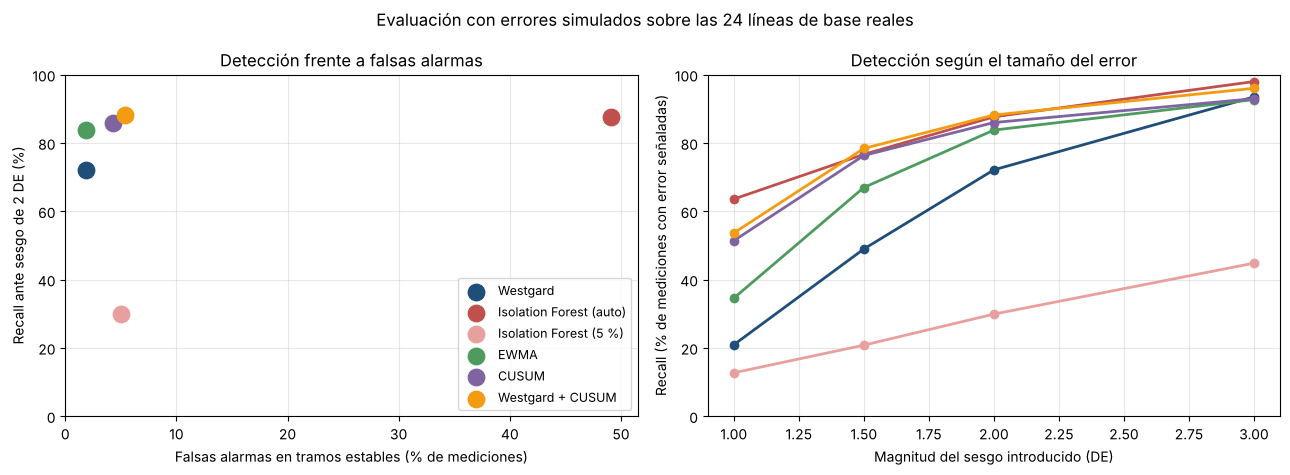

In [59]:
from pathlib import Path
RUTA_RESULTADOS = Path("results")
RUTA_RESULTADOS.mkdir(exist_ok=True)

colores = {
    "Westgard": "#1f4e79",
    "Isolation Forest (auto)": "#c0504d",
    "Isolation Forest (5 %)": "#e8a09e",
    "EWMA": "#4f9a5f",
    "CUSUM": "#8064a2",
    "Westgard + CUSUM": "#f39c12",
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Panel 1: recall frente a falsas alarmas (sesgo de 2 DE)
ax = axes[0]
ref = metricas_sim.loc[metricas_sim["Escenario"] == "Sesgo 2 DE"]
for m in metodos_sim:
    x = falsas_alarmas.set_index("Método").loc[
        m, "Falsas alarmas por medición (%)"]
    y = ref.set_index("Método").loc[m, "Recall"] * 100
    ax.scatter(x, y, s=140, color=colores[m], label=m, zorder=3)
ax.set_xlabel("Falsas alarmas en tramos estables (% de mediciones)")
ax.set_ylabel("Recall ante sesgo de 2 DE (%)")
ax.set_title("Detección frente a falsas alarmas")
ax.grid(alpha=0.3)
ax.set_xlim(left=0)
ax.set_ylim(0, 100)
ax.legend(fontsize=9, loc="lower right")

# Panel 2: recall según magnitud del sesgo
ax = axes[1]
orden_sesgos = ["Sesgo 1 DE", "Sesgo 1,5 DE", "Sesgo 2 DE", "Sesgo 3 DE"]
for m in metodos_sim:
    serie = (metricas_sim.loc[metricas_sim["Método"] == m]
             .set_index("Escenario").loc[orden_sesgos, "Recall"] * 100)
    ax.plot([1, 1.5, 2, 3], serie.values, marker="o",
            color=colores[m], label=m, lw=2)
ax.set_xlabel("Magnitud del sesgo introducido (DE)")
ax.set_ylabel("Recall (% de mediciones con error señaladas)")
ax.set_title("Detección según el tamaño del error")
ax.set_ylim(0, 100)
ax.grid(alpha=0.3)

fig.suptitle("Evaluación con errores simulados sobre las 24 líneas de base reales",
             fontsize=12)
fig.tight_layout()
fig.savefig(RUTA_RESULTADOS / "fig_simulacion_errores.png", dpi=150,
            bbox_inches="tight")
plt.show()

### 16.9. Selección del método y traducción a los indicadores del negocio

**Criterios de 2.3:**

| Método | 1. ¿Detecta más o antes que Westgard? | 2. ¿Falsas alarmas ≤ Westgard? | Decisión |
|---|---|---|---|
| Isolation Forest (por defecto) | Señala todos los episodios de inmediato, porque señala la mitad de todas las mediciones | No: 49,1 % frente a 1,8 % | Se descarta |
| Isolation Forest (5 %) | No: detecta alrededor de la mitad de los episodios de sesgo | No: 5,0 % | Se descarta |
| EWMA | Sí, en sesgos pequeños; no, en imprecisión | Similar: 1,9 % | Alternativa |
| CUSUM | Parcialmente: señala más mediciones con error que Westgard en sesgos de 1 a 2 DE y en imprecisión (igual con 3 DE), aunque ante imprecisión ×2 detecta menos episodios y más tarde. Mayor AUC en todos los escenarios | No por medición (4,3 %), sí por corrida (19,2 % frente a 29,8 %) | Complemento candidato |
| Westgard + CUSUM | Sí: recall 0,54–0,96 en sesgos | No: 5,4 % | Propuesta para evaluación prospectiva |

**Elección.** Ningún método cumple plenamente ambos criterios. **Westgard se mantiene como regla principal.** **Isolation Forest no se recomienda** con esta configuración: con el ajuste por defecto multiplica las falsas alarmas, con el ajuste al 5 % pierde detección, y su AUC no supera la distancia a la media. **CUSUM se selecciona como complemento candidato** para detectar desvíos sostenidos pequeños, con una evaluación prospectiva previa a su uso rutinario. Su interpretación en los datos reales exige, además, revisar la adecuación de la línea de base (15.2).

**Traducción a los indicadores propuestos en la preentrega (condiciones simuladas):**

- **Detección de errores (aproximación al KPI clínico).** Ante un sesgo simulado de 1,5 DE, Westgard no señala el 51 % de las mediciones con error; con Westgard + CUSUM, el 22 %. Describe una mejora de la detección simulada, no una reducción demostrada del riesgo para pacientes, que depende también de la revisión bioquímica y requiere evaluación prospectiva.
- **Tiempo de detección.** Ante sesgos de 2 DE, todos los métodos estadísticos señalan en una mediana de 3 a 4 mediciones (días hábiles). CUSUM no acorta ese tiempo, pero amplía la proporción de mediciones con error señaladas.
- **Carga de revisión (aproximación al KPI operativo).** Bajo la simulación, se esperan unas 1,2 mediciones estables señaladas por mes con Westgard, unas 3,4 con Westgard + CUSUM y unas 31 con Isolation Forest por defecto. Son mediciones señaladas, no episodios independientes ni repeticiones realizadas. Si el laboratorio repitiera el control ante cada una, multiplicar ese número por el costo de una repetición (reactivo, calibrador y tiempo del profesional) daría una cota superior del costo mensual.

Estas cifras surgen de condiciones favorables y no reemplazan una evaluación prospectiva con los episodios documentados.

## 17. Limitaciones del análisis

Los datos corresponden a un único equipo y nivel de control elaborado con pools de sueros. Los resultados no pueden generalizarse directamente a otros equipos, concentraciones o materiales.

Los datos abarcan aproximadamente dos años, del 26/08/2024 al 31/08/2026, por lo que no permiten evaluar patrones estacionales ni comportamientos de largo plazo. Además, cada pool se analiza por separado y los pools evaluados abarcan entre uno y cuatro meses de mediciones, lo que limita la cantidad de datos disponible para cada modelo y referencia.

Las medias y DE se estimaron con las primeras 20 mediciones de cada analito y pool. Los cambios de nivel o eventos presentes en ese período pueden afectar la referencia y las señales posteriores.

No se dispone de una clasificación independiente de las mediciones reales como normales o anómalas. Westgard se utilizó como comparador, no como verdad de referencia; por ello, recall, precisión, F1, AUC y falsas alarmas se estimaron solo con errores simulados (16). Esa simulación supone mediciones independientes con distribución normal y líneas de base estables. Sus tasas corresponden a condiciones favorables y no a las del laboratorio. La carga operativa se expresa como mediciones estables señaladas por mes bajo la simulación, no como episodios ni repeticiones observadas; tampoco se dispone del costo de cada repetición para traducirla a montos.

Las señales dependen de la configuración de cada método. Isolation Forest se entrenó con 20 mediciones por analito y pool, utilizando únicamente el valor del control y `contamination="auto"`. Su alcance es exploratorio y no incorpora la secuencia temporal.

La revisión retrospectiva se centró en casos seleccionados de control interno. Aunque estos controles formaron parte de la validación habitual de resultados de pacientes, el análisis no incluyó los resultados de pacientes ni las acciones realizadas en cada corrida.

Los datos abarcan menos de tres años y se analizan como series de tiempo cortas por pool. Esta extensión no permite validar los métodos en períodos independientes del mismo pool ni evaluar efectos estacionales.

**Consideraciones éticas y de privacidad.** El análisis utilizó solo resultados del material de control, sin datos de pacientes, con autorización de la dirección técnica. El archivo publicado no contiene identificadores personales. Ningún método reemplaza la validación profesional: la decisión de liberar resultados sigue siendo del bioquímico. Un método con exceso de falsas alarmas puede generar fatiga de alertas y que se ignoren señales relevantes, y uno con baja detección puede generar una confianza indebida. Por eso, cualquier incorporación requiere una evaluación prospectiva documentada.

## 18. Conclusiones

La comparación de Westgard, Isolation Forest, EWMA y CUSUM permitió identificar diferencias en las mediciones señaladas. La revisión de casos mostró la importancia de considerar la secuencia de resultados y la adecuación de la línea de base para interpretar esas señales.

Con la configuración utilizada, Isolation Forest señaló mediciones adicionales a Westgard, incluidas algunas próximas a la media, pero no identificó de manera continua ciertas secuencias señaladas por este último. Los resultados no permiten demostrar que esas alertas adicionales aporten una detección más útil ni justificar su incorporación rutinaria.

EWMA y CUSUM aportaron información sobre desviaciones sostenidas y su acumulación, aunque sus señales también dependen de la referencia utilizada.

La evaluación con errores simulados (16) permitió cuantificar las métricas propuestas en la preentrega. Isolation Forest, con el valor como única variable, no superó a la distancia a la media en capacidad de discriminación (AUC). Con el ajuste por defecto, señaló alrededor de 31 mediciones estables por mes en la simulación, frente a 1,2 de Westgard, y con el ajuste al 5 % no detectó cerca de la mitad de los episodios de sesgo. CUSUM obtuvo el mayor AUC y, en la simulación, mejoró la detección de sesgos pequeños, con un aumento moderado de las mediciones estables señaladas.

El principal aporte del trabajo es integrar los resultados de distintos métodos con la evolución del control y los eventos registrados, como apoyo a la revisión bioquímica, y cuantificar en condiciones controladas el equilibrio entre detección y falsas alarmas. Para confirmar la utilidad operativa de CUSUM, sería necesario evaluar sus alertas de forma prospectiva, con criterios independientes previamente definidos.

### 18.1. Respuesta a las hipótesis

- **H1 (Westgard e Isolation Forest señalan mediciones diferentes):** se confirma. De las 592 mediciones de seguimiento, 26 fueron señaladas solo por Westgard y 270 solo por Isolation Forest. Westgard detectó secuencias sostenidas con valores próximos a la media, mientras que Isolation Forest evaluó cada valor de forma aislada.

- **H2 (EWMA y CUSUM aportan información sobre desviaciones sostenidas):** se confirma parcialmente. En Cl del pool 10, CUSUM identificó un desplazamiento positivo persistente que Westgard señaló solo en cuatro mediciones. Sin embargo, en K del pool 7 sus señales reflejaron principalmente una línea de base con dos niveles, por lo que su utilidad depende de la adecuación de la referencia. En la evaluación con errores simulados (16), CUSUM señaló una mayor proporción de mediciones con sesgos de 1 a 1,5 DE que Westgard.

- **H3 (algunas señales adicionales de Isolation Forest aportan información útil):** no pudo confirmarse con los casos revisados. No se obtuvo evidencia suficiente de que esas señales identificaran desvíos relevantes adicionales a Westgard. La simulación de 10.5 mostró sensibilidad al umbral en un escenario estable. La evaluación con errores simulados (16) no mostró una ventaja de Isolation Forest: su puntaje no superó a |z| en AUC, y sus dos configuraciones no cumplieron el criterio de falsas alarmas.

### 18.2. Recomendaciones y aplicación potencial

1. **Mantener Westgard como regla principal** y la revisión bioquímica vigente.
2. **No incorporar Isolation Forest de forma rutinaria** con la configuración evaluada, de una única variable.
3. **Evaluar CUSUM de forma prospectiva como complemento** para desvíos sostenidos pequeños (k = 0,5; h = 5): registrar cada alerta, su verificación y su resolución, y comparar al cabo de algunos meses su tasa real de falsas alarmas con la estimada en 16.4.
4. **Revisar la adecuación de la línea de base** antes de fijar las referencias de un pool nuevo, considerando los cambios de nivel descriptos en 8.4.
5. **Documentar en la planilla** los episodios investigados, las acciones realizadas y su resolución. Esto permitiría, en el futuro, calcular las métricas con datos reales e incorporar el costo de cada repetición.
6. **Utilizar las tablas comparativas** de `results/` como apoyo para localizar las mediciones y secuencias que requieren atención.

**Escalabilidad.** El procedimiento puede aplicarse a otros analitos o equipos con un registro similar, revisando los parámetros y repitiendo la evaluación de 16 con sus propias líneas de base.

## 19. Exportación de resultados

Se guardan en la carpeta `results/` las tablas y figuras utilizadas en el informe, para su consulta sin ejecutar el notebook.

In [60]:
from pathlib import Path

RUTA_RESULTADOS = Path("results")
RUTA_RESULTADOS.mkdir(exist_ok=True)

tablas = {
    # Datos y calidad
    "calidad_duplicados_excluidos.csv": duplicados_excluidos,
    "linea_base_parametros.csv": parametros_base,
    # Resultados sobre los datos reales
    "westgard_resumen_por_serie.csv": resumen_westgard,
    "isolation_forest_resumen_por_serie.csv": resumen_senales_if,
    "comparacion_westgard_if_por_serie.csv": resumen_comparacion,
    "cuatro_metodos_resumen_por_serie.csv": resumen_cuatro_metodos,
    "cuatro_metodos_resumen_global.csv": resumen_global,
    "cuatro_metodos_coincidencias.csv": resumen_coincidencias,
    "senales_por_medicion.csv": df_cuatro_metodos[[
        "fecha", "analito", "pool_id", "numero_medicion", "valor",
        "media_base", "de_base", "z", "regla_1_3s", "regla_2_2s",
        "regla_4_1s", "regla_10x", "alerta_westgard", "puntaje_if",
        "alerta_if", "alerta_ewma", "alerta_cusum", "comentario",
    ]],
    # Evaluación con errores simulados
    "simulacion_falsas_alarmas.csv": falsas_alarmas,
    "simulacion_metricas_deteccion.csv": metricas_sim,
    "simulacion_auc.csv": auc_sim,
}

for nombre, tabla in tablas.items():
    tabla.to_csv(RUTA_RESULTADOS / nombre, index=False, encoding="utf-8-sig")

print(f"Tablas guardadas en {RUTA_RESULTADOS}/:")
for nombre in tablas:
    print("  -", nombre)

Tablas guardadas en results/:
  - calidad_duplicados_excluidos.csv
  - linea_base_parametros.csv
  - westgard_resumen_por_serie.csv
  - isolation_forest_resumen_por_serie.csv
  - comparacion_westgard_if_por_serie.csv
  - cuatro_metodos_resumen_por_serie.csv
  - cuatro_metodos_resumen_global.csv
  - cuatro_metodos_coincidencias.csv
  - senales_por_medicion.csv
  - simulacion_falsas_alarmas.csv
  - simulacion_metricas_deteccion.csv
  - simulacion_auc.csv


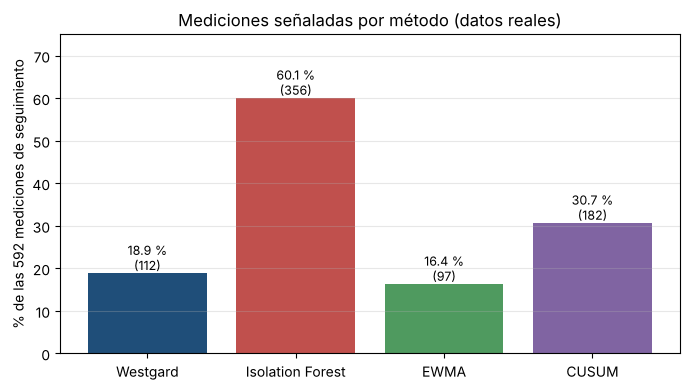

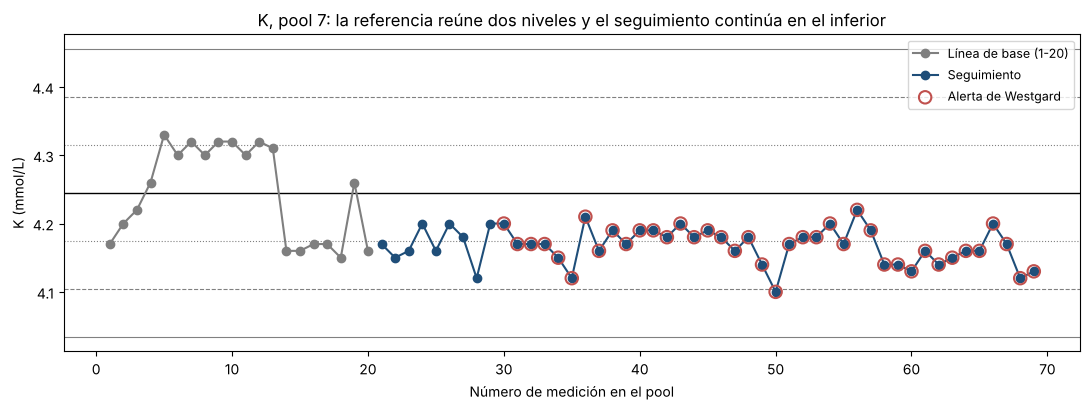

Figuras guardadas: ['fig_frecuencia_senales.png', 'fig_k_pool7_levey_jennings.png', 'fig_simulacion_errores.png']


In [61]:
# Figura 1: frecuencia de señales por método en los datos reales
fig, ax = plt.subplots(figsize=(7, 4))
orden = ["Westgard", "Isolation_Forest", "EWMA", "CUSUM"]
datos_fig = resumen_global.set_index("Metodo").loc[orden]
barras = ax.bar(
    ["Westgard", "Isolation Forest", "EWMA", "CUSUM"],
    datos_fig["Porcentaje_con_senal"],
    color=["#1f4e79", "#c0504d", "#4f9a5f", "#8064a2"],
)
for barra, n in zip(barras, datos_fig["Registros_con_senal"]):
    ax.annotate(f"{barra.get_height():.1f} %\n({n})",
                (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                ha="center", va="bottom", fontsize=9)
ax.set_ylabel("% de las 592 mediciones de seguimiento")
ax.set_ylim(0, 75)
ax.set_title("Mediciones señaladas por método (datos reales)")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(RUTA_RESULTADOS / "fig_frecuencia_senales.png", dpi=150)
plt.show()

# Figura 2: carta de Levey-Jennings de K del pool 7
k7 = df.loc[(df["analito"] == "K") & (df["pool_id"] == 7)].sort_values("numero_medicion")
k7_seg = df_cuatro_metodos.loc[
    (df_cuatro_metodos["analito"] == "K") & (df_cuatro_metodos["pool_id"] == 7)
]
media_k7 = k7_seg["media_base"].iloc[0]
de_k7 = k7_seg["de_base"].iloc[0]

fig, ax = plt.subplots(figsize=(11, 4.2))
for n_de, estilo in [(1, ":"), (2, "--"), (3, "-")]:
    for signo in (1, -1):
        ax.axhline(media_k7 + signo * n_de * de_k7, color="grey",
                   ls=estilo, lw=0.8)
ax.axhline(media_k7, color="black", lw=1)
base_k7 = k7.loc[k7["numero_medicion"] <= 20]
ax.plot(base_k7["numero_medicion"], base_k7["valor"], "o-",
        color="#7f7f7f", label="Línea de base (1-20)")
ax.plot(k7_seg["numero_medicion"], k7_seg["valor"], "o-",
        color="#1f4e79", label="Seguimiento")
alertas_k7 = k7_seg.loc[k7_seg["alerta_westgard"]]
ax.scatter(alertas_k7["numero_medicion"], alertas_k7["valor"], s=80,
           facecolors="none", edgecolors="#c0504d", lw=1.5,
           label="Alerta de Westgard", zorder=3)
ax.set_xlabel("Número de medición en el pool")
ax.set_ylabel("K (mmol/L)")
ax.set_title("K, pool 7: la referencia reúne dos niveles y el seguimiento "
             "continúa en el inferior")
ax.legend(fontsize=9, loc="upper right")
fig.tight_layout()
fig.savefig(RUTA_RESULTADOS / "fig_k_pool7_levey_jennings.png", dpi=150)
plt.show()

print("Figuras guardadas:",
      sorted(p.name for p in RUTA_RESULTADOS.glob("*.png")))

## 20. Bibliografía

1. Westgard, J. O., Barry, P. L., Hunt, M. R., y Groth, T. (1981). A multi-rule Shewhart chart for quality control in clinical chemistry. *Clinical Chemistry, 27*(3), 493–501. https://doi.org/10.1093/clinchem/27.3.493

2. Westgard QC. (s. f.). “Westgard Rules” and Multirule Quality Control. https://www.westgard.com/westgard-rules.html

3. Liu, F. T., Ting, K. M., y Zhou, Z.-H. (2008). Isolation Forest. *2008 Eighth IEEE International Conference on Data Mining*, 413–422. https://doi.org/10.1109/ICDM.2008.17

4. Scikit-learn developers. (s. f.). IsolationForest. *Documentación de scikit-learn*. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html

5. NIST/SEMATECH. (s. f.). EWMA Control Charts. En *e-Handbook of Statistical Methods*. https://www.itl.nist.gov/div898/handbook/pmc/section3/pmc324.htm

6. NIST/SEMATECH. (s. f.). CUSUM Control Charts. En *e-Handbook of Statistical Methods*. https://www.itl.nist.gov/div898/handbook/pmc/section3/pmc323.htm

7. Scikit-learn developers. (s. f.). roc_auc_score. *Documentación de scikit-learn*. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html